# Global Investment Decision Engine
## Phase 1 — Data Audit

Objective:
Understand the available financial data before designing the
valuation and investment analysis.

Tools:
- Python
- Pandas
- NumPy

In [1]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 2.2.3
NumPy version: 2.1.3


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Currencies and Country EconomyWise.csv to Currencies and Country EconomyWise.csv
Saving Financial Statements.csv to Financial Statements.csv
Saving Historical Data.csv to Historical Data.csv


In [3]:
import os

print(os.listdir("/content"))

['.config', 'Financial Statements.csv', 'Currencies and Country EconomyWise.csv', 'Historical Data.csv', 'sample_data']


In [4]:
financial_file = "/content/Financial Statements.csv"

df = pd.read_csv(financial_file)

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully.
Rows: 161
Columns: 23


In [5]:
df.head()

,Year,Company,Category,Market Cap(in B USD),Revenue,Gross Profit,Net Income,Earning Per Share,EBITDA,Share Holder Equity,Cash Flow from Operating,Cash Flow from Investing,Cash Flow from Financial Activities,Current Ratio,Debt/Equity Ratio,ROE,ROA,ROI,Net Profit Margin,Free Cash Flow per Share,Return on Tangible Equity,Number of Employees,Inflation Rate(in US)
0,2022,AAPL,IT,2066.94,394328.0,170782.0,99803.0,6.11,130541.0,50672.0,122151.0,-22354.0,-110749.0,0.8794,2.3695,196.9589,28.2924,66.6994,25.3096,1.3146,196.9589,164000,8.0028
1,2021,AAPL,IT,2913.28,365817.0,152836.0,94680.0,5.61,120233.0,63090.0,104038.0,-14545.0,-93353.0,1.0746,1.9768,150.0713,26.9742,54.9839,25.8818,1.3261,150.0713,154000,4.6979
2,2020,AAPL,IT,2255.97,274515.0,104956.0,57411.0,3.28,77344.0,65339.0,80674.0,-4289.0,-86820.0,1.3636,1.7208,87.8664,17.7256,35.0054,20.9136,1.0183,87.8664,147000,1.2336
3,2019,AAPL,IT,1304.76,260174.0,98392.0,55256.0,2.97,76477.0,90488.0,69391.0,45896.0,-90976.0,1.5401,1.1940,61.0645,16.3230,30.3113,21.2381,-0.0388,61.0645,137000,1.8122
4,2018,AAPL,IT,748.54,265595.0,101839.0,59531.0,2.98,81801.0,107147.0,77434.0,16066.0,-87876.0,1.1329,1.0685,55.5601,16.2775,29.6348,22.4142,0.7414,55.5601,132000,2.4426


In [6]:
df.sample(5, random_state=42)

,Year,Company,Category,Market Cap(in B USD),Revenue,Gross Profit,Net Income,Earning Per Share,EBITDA,Share Holder Equity,Cash Flow from Operating,Cash Flow from Investing,Cash Flow from Financial Activities,Current Ratio,Debt/Equity Ratio,ROE,ROA,ROI,Net Profit Margin,Free Cash Flow per Share,Return on Tangible Equity,Number of Employees,Inflation Rate(in US)
105,2021,BCS,BANK,43.60,30169.69,30169.69,8766.263,2.0131,1.0,96547.15,67268.52,5871.6770,147.1357,1.0000,6.3396,10.2918,0.5220,1.6696,28.2167,-1.4283,11.6267,81600,4.6979
108,2018,BCS,BANK,31.68,28212.33,28212.33,1860.711,0.4912,1.0,85132.21,11351.14,903.6596,-9059.2880,1.0000,5.8975,3.7191,0.2093,0.6186,7.0877,-15.5712,4.2504,83500,2.4426
142,2013,INTC,ELEC,129.02,52708.00,31521.00,9620.000,1.8900,20323.0,58256.00,20776.00,-18073.0000,-5498.0000,2.3647,0.2308,16.5133,10.4160,13.4694,18.2515,0.4520,22.5859,107600,1.4648
55,2019,AIG,Bank,44.65,49746.00,11975.00,3326.000,3.7400,11817.0,67427.00,-1807.00,-5475.0000,7258.0000,1.0000,0.5243,6.1561,0.7849,4.0097,6.6860,-1.5986,6.1118,46000,1.8122
94,2018,MCD,FOOD,148.82,21257.90,10832.60,5924.300,7.5400,10304.6,-6258.40,6966.70,-2455.1000,-5949.6000,1.3631,-4.9654,-94.6616,18.0557,23.8720,27.8687,0.8436,-68.9682,210000,2.4426


In [7]:
print("Number of columns:", len(df.columns))

for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

Number of columns: 23
1. Year
2. Company 
3. Category
4. Market Cap(in B USD)
5. Revenue
6. Gross Profit
7. Net Income
8. Earning Per Share
9. EBITDA
10. Share Holder Equity
11. Cash Flow from Operating
12. Cash Flow from Investing
13. Cash Flow from Financial Activities
14. Current Ratio
15. Debt/Equity Ratio
16. ROE
17. ROA
18. ROI
19. Net Profit Margin
20. Free Cash Flow per Share
21. Return on Tangible Equity
22. Number of Employees
23. Inflation Rate(in US)


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 161 entries, 0 to 160
Data columns (total 23 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Year                                 161 non-null    int64  
 1   Company                              161 non-null    object 
 2   Category                             161 non-null    object 
 3   Market Cap(in B USD)                 160 non-null    float64
 4   Revenue                              161 non-null    float64
 5   Gross Profit                         161 non-null    float64
 6   Net Income                           161 non-null    float64
 7   Earning Per Share                    161 non-null    float64
 8   EBITDA                               161 non-null    float64
 9   Share Holder Equity                  161 non-null    float64
 10  Cash Flow from Operating             161 non-null    float64
 11  Cash Flow from Investing        

In [9]:
print("Minimum year:", df["Year"].min())
print("Maximum year:", df["Year"].max())

print("\nYears available:")
print(sorted(df["Year"].unique()))

Minimum year: 2009
Maximum year: 2023

Years available:
[np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]


In [10]:
for col in df.columns:
    print(repr(col))

'Year'
'Company '
'Category'
'Market Cap(in B USD)'
'Revenue'
'Gross Profit'
'Net Income'
'Earning Per Share'
'EBITDA'
'Share Holder Equity'
'Cash Flow from Operating'
'Cash Flow from Investing'
'Cash Flow from Financial Activities'
'Current Ratio'
'Debt/Equity Ratio'
'ROE'
'ROA'
'ROI'
'Net Profit Margin'
'Free Cash Flow per Share'
'Return on Tangible Equity'
'Number of Employees'
'Inflation Rate(in US)'


In [11]:
# Remove accidental leading/trailing spaces from column names
df.columns = df.columns.str.strip()

print("Column names cleaned successfully.")
print(df.columns.tolist())

Column names cleaned successfully.
['Year', 'Company', 'Category', 'Market Cap(in B USD)', 'Revenue', 'Gross Profit', 'Net Income', 'Earning Per Share', 'EBITDA', 'Share Holder Equity', 'Cash Flow from Operating', 'Cash Flow from Investing', 'Cash Flow from Financial Activities', 'Current Ratio', 'Debt/Equity Ratio', 'ROE', 'ROA', 'ROI', 'Net Profit Margin', 'Free Cash Flow per Share', 'Return on Tangible Equity', 'Number of Employees', 'Inflation Rate(in US)']


In [12]:
print("Number of unique companies:", df["Company"].nunique())

print("\nCompanies:")
for company in sorted(df["Company"].unique()):
    print("-", company)

Number of unique companies: 12

Companies:
- AAPL
- AIG
- AMZN
- BCS
- GOOG
- INTC
- MCD
- MSFT
- NVDA
- PCG
- PYPL
- SHLDQ


In [13]:
company_counts = (
    df.groupby("Company")
      .agg(
          observations=("Year", "count"),
          first_year=("Year", "min"),
          last_year=("Year", "max")
      )
      .sort_values("observations", ascending=False)
)

company_counts

,observations,first_year,last_year
Company,,,
NVDA,15,2009,2023
MSFT,15,2009,2023
AAPL,14,2009,2022
AIG,14,2009,2022
BCS,14,2009,2022
AMZN,14,2009,2022
INTC,14,2009,2022
GOOG,14,2009,2022
MCD,14,2009,2022


In [14]:
print("Number of categories:", df["Category"].nunique())

print("\nCategories:")
for category in sorted(df["Category"].unique()):
    print("-", category)

Number of categories: 9

Categories:
- BANK
- Bank
- ELEC
- FOOD
- FinTech
- Finance
- IT
- LOGI
- Manufacturing


In [15]:
duplicates = df[
    df.duplicated(
        subset=["Company", "Year"],
        keep=False
    )
]

print("Duplicate Company-Year rows:", len(duplicates))

duplicates

Duplicate Company-Year rows: 0


,Year,Company,Category,Market Cap(in B USD),Revenue,Gross Profit,Net Income,Earning Per Share,EBITDA,Share Holder Equity,Cash Flow from Operating,Cash Flow from Investing,Cash Flow from Financial Activities,Current Ratio,Debt/Equity Ratio,ROE,ROA,ROI,Net Profit Margin,Free Cash Flow per Share,Return on Tangible Equity,Number of Employees,Inflation Rate(in US)


In [16]:
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2)
})

missing[missing["Missing Count"] > 0]

,Missing Count,Missing %
Market Cap(in B USD),1,0.62


In [17]:
print("Categories:")
print(sorted(df["Category"].unique()))

Categories:
['BANK', 'Bank', 'ELEC', 'FOOD', 'FinTech', 'Finance', 'IT', 'LOGI', 'Manufacturing']


In [18]:
category_counts = (
    df.groupby("Category")["Company"]
      .nunique()
      .sort_values(ascending=False)
)

category_counts

,Company
Category,
IT,3
ELEC,2
BANK,1
FOOD,1
Bank,1
FinTech,1
Finance,1
LOGI,1
Manufacturing,1


In [19]:
financial_columns = [
    "Market Cap(in B USD)",
    "Revenue",
    "Gross Profit",
    "Net Income",
    "EBITDA",
    "Share Holder Equity",
    "Cash Flow from Operating",
    "Cash Flow from Investing",
    "Cash Flow from Financial Activities",
    "Current Ratio",
    "Debt/Equity Ratio",
    "ROE",
    "ROA",
    "ROI",
    "Net Profit Margin",
    "Free Cash Flow per Share",
    "Return on Tangible Equity",
    "Number of Employees",
    "Inflation Rate(in US)"
]

df[financial_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Market Cap(in B USD),160.0,337.604312,541.102812,0.0400,41.1550,113.1400,357.1075,2.913280e+03
Revenue,161.0,75862.600758,90786.895983,3326.4450,22820.4000,45992.0400,77849.0000,5.139830e+05
Gross Profit,161.0,37383.463124,41669.093697,1174.2690,10396.0000,19561.0000,47722.0000,2.251520e+05
Net Income,161.0,12276.607076,19417.421119,-12244.0000,844.0000,4757.8000,14136.0000,9.980300e+04
EBITDA,161.0,20174.023974,26342.029803,-6860.0000,2310.0000,9958.0000,27765.0000,1.305410e+05
Share Holder Equity,161.0,57178.005273,54098.208311,-8210.3000,12353.0000,47791.0000,91570.7000,2.561440e+05
Cash Flow from Operating,161.0,20790.317839,27300.212516,-39392.2700,3502.0000,7386.7000,31626.0000,1.221510e+05
Cash Flow from Investing,161.0,-9581.533232,16196.808177,-59611.0000,-17434.0000,-5904.0000,-981.6000,4.974900e+04
Cash Flow from Financial Activities,161.0,-8598.157950,20281.662795,-110749.0000,-9059.2880,-1408.0000,735.3000,2.592800e+04
Current Ratio,161.0,2.035368,1.660894,0.2205,1.0000,1.3412,2.4734,1.061780e+01


In [20]:
df[
    [
        "Company",
        "Year",
        "Revenue",
        "Gross Profit",
        "Net Income",
        "EBITDA",
        "Share Holder Equity",
        "Cash Flow from Operating",
        "Cash Flow from Investing",
        "Cash Flow from Financial Activities"
    ]
].head(15)

,Company,Year,Revenue,Gross Profit,Net Income,EBITDA,Share Holder Equity,Cash Flow from Operating,Cash Flow from Investing,Cash Flow from Financial Activities
0,AAPL,2022,394328.0,170782.0,99803.0,130541.0,50672.0,122151.0,-22354.0,-110749.0
1,AAPL,2021,365817.0,152836.0,94680.0,120233.0,63090.0,104038.0,-14545.0,-93353.0
2,AAPL,2020,274515.0,104956.0,57411.0,77344.0,65339.0,80674.0,-4289.0,-86820.0
3,AAPL,2019,260174.0,98392.0,55256.0,76477.0,90488.0,69391.0,45896.0,-90976.0
4,AAPL,2018,265595.0,101839.0,59531.0,81801.0,107147.0,77434.0,16066.0,-87876.0
5,AAPL,2017,229234.0,88186.0,48351.0,71501.0,134047.0,64225.0,-46446.0,-17974.0
6,AAPL,2016,215639.0,84263.0,45687.0,70529.0,128249.0,66231.0,-45977.0,-20890.0
7,AAPL,2015,233715.0,93626.0,53394.0,82487.0,119355.0,81266.0,-56274.0,-17716.0
8,AAPL,2014,182795.0,70537.0,39510.0,60449.0,111547.0,59713.0,-22579.0,-37549.0
9,AAPL,2013,170910.0,64304.0,37037.0,55756.0,123549.0,53666.0,-33774.0,-16379.0


In [21]:
df[
    [
        "Company",
        "Year",
        "Revenue",
        "Gross Profit",
        "Net Income",
        "EBITDA",
        "Share Holder Equity",
        "Cash Flow from Operating",
        "Cash Flow from Investing",
        "Cash Flow from Financial Activities"
    ]
].tail(15)

,Company,Year,Revenue,Gross Profit,Net Income,EBITDA,Share Holder Equity,Cash Flow from Operating,Cash Flow from Investing,Cash Flow from Financial Activities
146,INTC,2009,35127.0,19561.0,4369.0,10763.0,41704.0,11170.0,-7965.0,-2568.0
147,AMZN,2022,513983.0,225152.0,-2722.0,54169.0,146043.0,46752.0,-37601.0,9718.0
148,AMZN,2021,469822.0,197478.0,33364.0,59312.0,138245.0,46327.0,-58154.0,6291.0
149,AMZN,2020,386064.0,152757.0,21331.0,48079.0,93404.0,66064.0,-59611.0,-1104.0
150,AMZN,2019,280522.0,114986.0,11588.0,36330.0,62060.0,38514.0,-24281.0,-10066.0
151,AMZN,2018,232887.0,93731.0,10073.0,27762.0,43549.0,30723.0,-12369.0,-7686.0
152,AMZN,2017,177866.0,65932.0,3033.0,15584.0,27709.0,18365.0,-27084.0,9928.0
153,AMZN,2016,135987.0,47722.0,2371.0,12302.0,19285.0,17203.0,-9516.0,-3716.0
154,AMZN,2015,107006.0,35355.0,596.0,8514.0,13384.0,12039.0,-6450.0,-3882.0
155,AMZN,2014,88988.0,26236.0,-241.0,4924.0,10741.0,6842.0,-5065.0,4432.0


In [22]:
historical_file = "/content/Historical Data.csv"

historical_df = pd.read_csv(historical_file)

print("Historical Data loaded successfully.")
print("Rows:", historical_df.shape[0])
print("Columns:", historical_df.shape[1])

Historical Data loaded successfully.
Rows: 6722
Columns: 22


In [23]:
print("Columns:")
for i, col in enumerate(historical_df.columns, start=1):
    print(f"{i}. {col}")

Columns:
1. Date
2. USD/EUR
3. USD/GBP
4. USD/JPY
5. USD/CHF
6. USD/CAD
7. USD/AUD
8. USD/SGD
9. USD/KRW
10. USD/CNY
11. USD/INR
12. USD/BRL
13. USD/ZAR
14. USD/RUB
15. USD/MXN
16. USD/IDR
17. USD/TRY
18. USD/VND
19. USD/LKR
20. USD/NGN 
21. USD/KES
22. USD/BDT


In [24]:
historical_df.head()

,Date,USD/EUR,USD/GBP,USD/JPY,USD/CHF,USD/CAD,USD/AUD,USD/SGD,USD/KRW,USD/CNY,USD/INR,USD/BRL,USD/ZAR,USD/RUB,USD/MXN,USD/IDR,USD/TRY,USD/VND,USD/LKR,USD/NGN,USD/KES,USD/BDT
0,16-05-2006,0.778,0.530,109.76,1.208,1.107,1.304,1.574,929.97,7.993,44.995,2.142,6.330,26.994,11.005,9188.6,1.446,15965.0,98.296,122.64,68.578,66.690
1,17-05-2006,0.785,0.531,110.91,1.215,1.115,1.317,1.580,925.29,7.991,44.625,2.183,6.434,26.950,11.171,8978.9,1.477,15507.0,102.750,124.57,69.803,67.709
2,18-05-2006,0.778,0.528,110.90,1.205,1.120,1.309,1.578,933.81,8.000,45.400,2.202,6.448,27.021,11.151,9124.9,1.498,15204.0,102.750,122.24,68.687,66.416
3,19-05-2006,0.783,0.532,111.66,1.218,1.117,1.321,1.583,933.02,8.010,45.295,2.197,6.481,27.053,11.138,9189.2,1.478,15302.0,102.760,123.01,69.189,65.529
4,22-05-2006,0.778,0.530,111.46,1.205,1.117,1.327,1.585,939.40,8.016,45.290,2.297,6.526,27.060,11.244,9242.7,1.535,15310.0,102.750,123.08,68.814,66.363


In [25]:
# Standardize text fields

df["Company"] = df["Company"].str.strip()
df["Category"] = df["Category"].str.strip().str.upper()

print("Companies:")
print(sorted(df["Company"].unique()))

print("\nCategories:")
print(sorted(df["Category"].unique()))

Companies:
['AAPL', 'AIG', 'AMZN', 'BCS', 'GOOG', 'INTC', 'MCD', 'MSFT', 'NVDA', 'PCG', 'PYPL', 'SHLDQ']

Categories:
['BANK', 'ELEC', 'FINANCE', 'FINTECH', 'FOOD', 'IT', 'LOGI', 'MANUFACTURING']


In [26]:
print(df["Category"].value_counts())

Category
IT               43
ELEC             29
BANK             28
MANUFACTURING    14
LOGI             14
FOOD             14
FINANCE          10
FINTECH           9
Name: count, dtype: int64


In [27]:
df[df["Market Cap(in B USD)"].isna()]

,Year,Company,Category,Market Cap(in B USD),Revenue,Gross Profit,Net Income,Earning Per Share,EBITDA,Share Holder Equity,Cash Flow from Operating,Cash Flow from Investing,Cash Flow from Financial Activities,Current Ratio,Debt/Equity Ratio,ROE,ROA,ROI,Net Profit Margin,Free Cash Flow per Share,Return on Tangible Equity,Number of Employees,Inflation Rate(in US)
51,2014,PYPL,FINTECH,NaN,8025.0,4218.0,419.0,0.34,1784.0,8248.0,2220.0,-2881.0,1284.0,1.3224,0.1325,5.08,1.9118,5.08,5.2212,0.103,8.5458,15800,1.6222


In [28]:
df["FCF_Proxy"] = (
    df["Cash Flow from Operating"] +
    df["Cash Flow from Investing"]
)

df[[
    "Company",
    "Year",
    "Cash Flow from Operating",
    "Cash Flow from Investing",
    "FCF_Proxy"
]].head(15)

,Company,Year,Cash Flow from Operating,Cash Flow from Investing,FCF_Proxy
0,AAPL,2022,122151.0,-22354.0,99797.0
1,AAPL,2021,104038.0,-14545.0,89493.0
2,AAPL,2020,80674.0,-4289.0,76385.0
3,AAPL,2019,69391.0,45896.0,115287.0
4,AAPL,2018,77434.0,16066.0,93500.0
5,AAPL,2017,64225.0,-46446.0,17779.0
6,AAPL,2016,66231.0,-45977.0,20254.0
7,AAPL,2015,81266.0,-56274.0,24992.0
8,AAPL,2014,59713.0,-22579.0,37134.0
9,AAPL,2013,53666.0,-33774.0,19892.0


In [29]:
df = df.sort_values(["Company", "Year"])

df["Revenue Growth"] = (
    df.groupby("Company")["Revenue"]
      .pct_change() * 100
)

df["EBITDA Margin"] = (
    df["EBITDA"] / df["Revenue"] * 100
)

df["Gross Margin"] = (
    df["Gross Profit"] / df["Revenue"] * 100
)

df["FCF Margin"] = (
    df["FCF_Proxy"] / df["Revenue"] * 100
)

df["EBITDA Growth"] = (
    df.groupby("Company")["EBITDA"]
      .pct_change() * 100
)

df["Net Income Growth"] = (
    df.groupby("Company")["Net Income"]
      .pct_change() * 100
)

df["FCF Growth"] = (
    df.groupby("Company")["FCF_Proxy"]
      .pct_change() * 100
)

In [30]:
df["Company"] = df["Company"].str.strip()
df["Category"] = df["Category"].str.strip().str.upper()

print(sorted(df["Company"].unique()))
print(sorted(df["Category"].unique()))

['AAPL', 'AIG', 'AMZN', 'BCS', 'GOOG', 'INTC', 'MCD', 'MSFT', 'NVDA', 'PCG', 'PYPL', 'SHLDQ']
['BANK', 'ELEC', 'FINANCE', 'FINTECH', 'FOOD', 'IT', 'LOGI', 'MANUFACTURING']


In [31]:
df[df["Market Cap(in B USD)"].isna()]

,Year,Company,Category,Market Cap(in B USD),Revenue,Gross Profit,Net Income,Earning Per Share,EBITDA,Share Holder Equity,Cash Flow from Operating,Cash Flow from Investing,Cash Flow from Financial Activities,Current Ratio,Debt/Equity Ratio,ROE,ROA,ROI,Net Profit Margin,Free Cash Flow per Share,Return on Tangible Equity,Number of Employees,Inflation Rate(in US),FCF_Proxy,Revenue Growth,EBITDA Margin,Gross Margin,FCF Margin,EBITDA Growth,Net Income Growth,FCF Growth
51,2014,PYPL,FINTECH,NaN,8025.0,4218.0,419.0,0.34,1784.0,8248.0,2220.0,-2881.0,1284.0,1.3224,0.1325,5.08,1.9118,5.08,5.2212,0.103,8.5458,15800,1.6222,-661.0,NaN,22.23053,52.560748,-8.23676,NaN,NaN,NaN


In [32]:
df["FCF_Proxy"] = (
    df["Cash Flow from Operating"] +
    df["Cash Flow from Investing"]
)

df[[
    "Company",
    "Year",
    "Cash Flow from Operating",
    "Cash Flow from Investing",
    "FCF_Proxy"
]].head(15)

,Company,Year,Cash Flow from Operating,Cash Flow from Investing,FCF_Proxy
13,AAPL,2009,10159.0,-17434.0,-7275.0
12,AAPL,2010,18595.0,-13854.0,4741.0
11,AAPL,2011,37529.0,-40419.0,-2890.0
10,AAPL,2012,50856.0,-48227.0,2629.0
9,AAPL,2013,53666.0,-33774.0,19892.0
8,AAPL,2014,59713.0,-22579.0,37134.0
7,AAPL,2015,81266.0,-56274.0,24992.0
6,AAPL,2016,66231.0,-45977.0,20254.0
5,AAPL,2017,64225.0,-46446.0,17779.0
4,AAPL,2018,77434.0,16066.0,93500.0


In [33]:
financial_check = df[
    [
        "Revenue",
        "Gross Profit",
        "Net Income",
        "EBITDA",
        "Share Holder Equity",
        "Cash Flow from Operating",
        "Cash Flow from Investing",
        "Cash Flow from Financial Activities"
    ]
].describe().T

financial_check

,count,mean,std,min,25%,50%,75%,max
Revenue,161.0,75862.600758,90786.895983,3326.445,22820.400,45992.04,77849.0,513983.0
Gross Profit,161.0,37383.463124,41669.093697,1174.269,10396.000,19561.00,47722.0,225152.0
Net Income,161.0,12276.607076,19417.421119,-12244.000,844.000,4757.80,14136.0,99803.0
EBITDA,161.0,20174.023974,26342.029803,-6860.000,2310.000,9958.00,27765.0,130541.0
Share Holder Equity,161.0,57178.005273,54098.208311,-8210.300,12353.000,47791.00,91570.7,256144.0
Cash Flow from Operating,161.0,20790.317839,27300.212516,-39392.270,3502.000,7386.70,31626.0,122151.0
Cash Flow from Investing,161.0,-9581.533232,16196.808177,-59611.000,-17434.000,-5904.00,-981.6,49749.0
Cash Flow from Financial Activities,161.0,-8598.157950,20281.662795,-110749.000,-9059.288,-1408.00,735.3,25928.0


In [34]:
print("Negative Revenue:", (df["Revenue"] < 0).sum())
print("Negative Gross Profit:", (df["Gross Profit"] < 0).sum())
print("Negative EBITDA:", (df["EBITDA"] < 0).sum())
print("Negative Net Income:", (df["Net Income"] < 0).sum())

Negative Revenue: 0
Negative Gross Profit: 0
Negative EBITDA: 9
Negative Net Income: 25


In [35]:
company_coverage = (
    df.groupby("Company")
      .agg(
          observations=("Year", "count"),
          first_year=("Year", "min"),
          last_year=("Year", "max")
      )
      .sort_values("observations", ascending=False)
)

company_coverage

,observations,first_year,last_year
Company,,,
NVDA,15,2009,2023
MSFT,15,2009,2023
AAPL,14,2009,2022
AIG,14,2009,2022
BCS,14,2009,2022
AMZN,14,2009,2022
INTC,14,2009,2022
GOOG,14,2009,2022
MCD,14,2009,2022


In [36]:
# Company-level screening for project selection

core_financials = [
    "Revenue",
    "Gross Profit",
    "Net Income",
    "EBITDA",
    "Share Holder Equity",
    "Cash Flow from Operating",
    "Cash Flow from Investing",
    "Cash Flow from Financial Activities"
]

company_screening = (
    df.groupby("Company")
      .agg(
          Years_Available=("Year", "nunique"),
          First_Year=("Year", "min"),
          Last_Year=("Year", "max"),
          Revenue_Availability=("Revenue", lambda x: x.notna().sum()),
          EBITDA_Availability=("EBITDA", lambda x: x.notna().sum()),
          Net_Income_Availability=("Net Income", lambda x: x.notna().sum()),
          Equity_Availability=("Share Holder Equity", lambda x: x.notna().sum()),
          Operating_CF_Availability=("Cash Flow from Operating", lambda x: x.notna().sum()),
          Investing_CF_Availability=("Cash Flow from Investing", lambda x: x.notna().sum())
      )
      .reset_index()
)

company_screening["Data_Completeness_%"] = (
    company_screening[
        [
            "Revenue_Availability",
            "EBITDA_Availability",
            "Net_Income_Availability",
            "Equity_Availability",
            "Operating_CF_Availability",
            "Investing_CF_Availability"
        ]
    ].mean(axis=1)
    / company_screening["Years_Available"]
    * 100
)

company_screening = company_screening.sort_values(
    ["Years_Available", "Data_Completeness_%"],
    ascending=False
)

company_screening

,Company,Years_Available,First_Year,Last_Year,Revenue_Availability,EBITDA_Availability,Net_Income_Availability,Equity_Availability,Operating_CF_Availability,Investing_CF_Availability,Data_Completeness_%
7,MSFT,15,2009,2023,15,15,15,15,15,15,100.0
8,NVDA,15,2009,2023,15,15,15,15,15,15,100.0
0,AAPL,14,2009,2022,14,14,14,14,14,14,100.0
1,AIG,14,2009,2022,14,14,14,14,14,14,100.0
2,AMZN,14,2009,2022,14,14,14,14,14,14,100.0
3,BCS,14,2009,2022,14,14,14,14,14,14,100.0
4,GOOG,14,2009,2022,14,14,14,14,14,14,100.0
5,INTC,14,2009,2022,14,14,14,14,14,14,100.0
6,MCD,14,2009,2022,14,14,14,14,14,14,100.0
9,PCG,14,2009,2022,14,14,14,14,14,14,100.0


In [37]:
# Add category information

company_categories = (
    df.groupby("Company")["Category"]
      .agg(lambda x: ", ".join(sorted(x.dropna().unique())))
      .reset_index()
      .rename(columns={"Category": "Category"})
)

company_screening = company_screening.merge(
    company_categories,
    on="Company",
    how="left"
)

company_screening

,Company,Years_Available,First_Year,Last_Year,Revenue_Availability,EBITDA_Availability,Net_Income_Availability,Equity_Availability,Operating_CF_Availability,Investing_CF_Availability,Data_Completeness_%,Category
0,MSFT,15,2009,2023,15,15,15,15,15,15,100.0,IT
1,NVDA,15,2009,2023,15,15,15,15,15,15,100.0,ELEC
2,AAPL,14,2009,2022,14,14,14,14,14,14,100.0,IT
3,AIG,14,2009,2022,14,14,14,14,14,14,100.0,BANK
4,AMZN,14,2009,2022,14,14,14,14,14,14,100.0,LOGI
5,BCS,14,2009,2022,14,14,14,14,14,14,100.0,BANK
6,GOOG,14,2009,2022,14,14,14,14,14,14,100.0,IT
7,INTC,14,2009,2022,14,14,14,14,14,14,100.0,ELEC
8,MCD,14,2009,2022,14,14,14,14,14,14,100.0,FOOD
9,PCG,14,2009,2022,14,14,14,14,14,14,100.0,MANUFACTURING


In [38]:
screening_view = company_screening[
    [
        "Company",
        "Category",
        "Years_Available",
        "First_Year",
        "Last_Year",
        "Revenue_Availability",
        "EBITDA_Availability",
        "Net_Income_Availability",
        "Equity_Availability",
        "Operating_CF_Availability",
        "Investing_CF_Availability",
        "Data_Completeness_%"
    ]
]

screening_view

,Company,Category,Years_Available,First_Year,Last_Year,Revenue_Availability,EBITDA_Availability,Net_Income_Availability,Equity_Availability,Operating_CF_Availability,Investing_CF_Availability,Data_Completeness_%
0,MSFT,IT,15,2009,2023,15,15,15,15,15,15,100.0
1,NVDA,ELEC,15,2009,2023,15,15,15,15,15,15,100.0
2,AAPL,IT,14,2009,2022,14,14,14,14,14,14,100.0
3,AIG,BANK,14,2009,2022,14,14,14,14,14,14,100.0
4,AMZN,LOGI,14,2009,2022,14,14,14,14,14,14,100.0
5,BCS,BANK,14,2009,2022,14,14,14,14,14,14,100.0
6,GOOG,IT,14,2009,2022,14,14,14,14,14,14,100.0
7,INTC,ELEC,14,2009,2022,14,14,14,14,14,14,100.0
8,MCD,FOOD,14,2009,2022,14,14,14,14,14,14,100.0
9,PCG,MANUFACTURING,14,2009,2022,14,14,14,14,14,14,100.0


In [39]:
print("Company categories:")
print(
    company_screening[["Company", "Category"]]
    .sort_values("Company")
    .to_string(index=False)
)

Company categories:
Company      Category
   AAPL            IT
    AIG          BANK
   AMZN          LOGI
    BCS          BANK
   GOOG            IT
   INTC          ELEC
    MCD          FOOD
   MSFT            IT
   NVDA          ELEC
    PCG MANUFACTURING
   PYPL       FINTECH
  SHLDQ       FINANCE


In [40]:
candidate_companies = company_screening[
    ~company_screening["Category"].isin(
        ["BANK", "FINANCE", "FINTECH"]
    )
].copy()

candidate_companies[
    [
        "Company",
        "Category",
        "Years_Available",
        "First_Year",
        "Last_Year",
        "Revenue_Availability",
        "EBITDA_Availability",
        "Net_Income_Availability",
        "Equity_Availability",
        "Operating_CF_Availability",
        "Investing_CF_Availability",
        "Data_Completeness_%"
    ]
].sort_values(
    ["Years_Available", "Data_Completeness_%"],
    ascending=False
)

,Company,Category,Years_Available,First_Year,Last_Year,Revenue_Availability,EBITDA_Availability,Net_Income_Availability,Equity_Availability,Operating_CF_Availability,Investing_CF_Availability,Data_Completeness_%
0,MSFT,IT,15,2009,2023,15,15,15,15,15,15,100.0
1,NVDA,ELEC,15,2009,2023,15,15,15,15,15,15,100.0
2,AAPL,IT,14,2009,2022,14,14,14,14,14,14,100.0
4,AMZN,LOGI,14,2009,2022,14,14,14,14,14,14,100.0
6,GOOG,IT,14,2009,2022,14,14,14,14,14,14,100.0
7,INTC,ELEC,14,2009,2022,14,14,14,14,14,14,100.0
8,MCD,FOOD,14,2009,2022,14,14,14,14,14,14,100.0
9,PCG,MANUFACTURING,14,2009,2022,14,14,14,14,14,14,100.0


In [41]:
print("Final non-financial candidates:")
print(
    candidate_companies[
        ["Company", "Category", "Years_Available", "Data_Completeness_%"]
    ].to_string(index=False)
)

Final non-financial candidates:
Company      Category  Years_Available  Data_Completeness_%
   MSFT            IT               15                100.0
   NVDA          ELEC               15                100.0
   AAPL            IT               14                100.0
   AMZN          LOGI               14                100.0
   GOOG            IT               14                100.0
   INTC          ELEC               14                100.0
    MCD          FOOD               14                100.0
    PCG MANUFACTURING               14                100.0


In [42]:
# Inspect the available financial fields for our shortlisted companies before selecting the final target.
candidate_list = candidate_companies["Company"].tolist()

candidate_data = df[
    df["Company"].isin(candidate_list)
].copy()

print("Candidate companies:", candidate_list)
print("Rows:", len(candidate_data))
print("Columns:", len(candidate_data.columns))

print("\nAll dataset columns:")
for i, col in enumerate(candidate_data.columns, start=1):
    print(f"{i}. {col}")

Candidate companies: ['MSFT', 'NVDA', 'AAPL', 'AMZN', 'GOOG', 'INTC', 'MCD', 'PCG']
Rows: 114
Columns: 31

All dataset columns:
1. Year
2. Company
3. Category
4. Market Cap(in B USD)
5. Revenue
6. Gross Profit
7. Net Income
8. Earning Per Share
9. EBITDA
10. Share Holder Equity
11. Cash Flow from Operating
12. Cash Flow from Investing
13. Cash Flow from Financial Activities
14. Current Ratio
15. Debt/Equity Ratio
16. ROE
17. ROA
18. ROI
19. Net Profit Margin
20. Free Cash Flow per Share
21. Return on Tangible Equity
22. Number of Employees
23. Inflation Rate(in US)
24. FCF_Proxy
25. Revenue Growth
26. EBITDA Margin
27. Gross Margin
28. FCF Margin
29. EBITDA Growth
30. Net Income Growth
31. FCF Growth


In [43]:
# Compare key financial-field coverage across the shortlisted companies before selecting the final target.
key_fields = [
    "Market Cap(in B USD)",
    "Revenue",
    "Gross Profit",
    "Net Income",
    "EBITDA",
    "Share Holder Equity",
    "Cash Flow from Operating",
    "Cash Flow from Investing",
    "Cash Flow from Financial Activities",
    "Current Ratio",
    "Debt/Equity Ratio",
    "FCF_Proxy"
]

coverage = (
    candidate_data.groupby("Company")[key_fields]
    .count()
    .assign(Years_Available=candidate_data.groupby("Company")["Year"].count())
)

coverage["Coverage_%"] = (
    coverage[key_fields].mean(axis=1)
    / coverage["Years_Available"]
    * 100
)

coverage = coverage.sort_values(
    ["Years_Available", "Coverage_%"],
    ascending=False
)

coverage

,Market Cap(in B USD),Revenue,Gross Profit,Net Income,EBITDA,Share Holder Equity,Cash Flow from Operating,Cash Flow from Investing,Cash Flow from Financial Activities,Current Ratio,Debt/Equity Ratio,FCF_Proxy,Years_Available,Coverage_%
Company,,,,,,,,,,,,,,
MSFT,15,15,15,15,15,15,15,15,15,15,15,15,15,100.0
NVDA,15,15,15,15,15,15,15,15,15,15,15,15,15,100.0
AAPL,14,14,14,14,14,14,14,14,14,14,14,14,14,100.0
AMZN,14,14,14,14,14,14,14,14,14,14,14,14,14,100.0
GOOG,14,14,14,14,14,14,14,14,14,14,14,14,14,100.0
INTC,14,14,14,14,14,14,14,14,14,14,14,14,14,100.0
MCD,14,14,14,14,14,14,14,14,14,14,14,14,14,100.0
PCG,14,14,14,14,14,14,14,14,14,14,14,14,14,100.0


In [46]:
# Compare MSFT and NVDA on profitability, growth, returns, and cash-flow stability to support the final company selection.
finalists = ["MSFT", "NVDA"]

comparison = (
    candidate_data[candidate_data["Company"].isin(finalists)]
    .groupby("Company")
    [
        [
            "Revenue Growth",
            "EBITDA Margin",
            "Net Profit Margin",
            "FCF Margin",
            "ROE",
            "ROA"
        ]
    ]
    .agg(["mean", "median", "std"])
    .round(2)
)

comparison

Revenue Growth               EBITDA Margin                \
                  mean median    std          mean median    std   
Company                                                            
MSFT              9.77   9.66   5.64         42.01  41.94   4.58   
NVDA             17.65   9.94  21.93         23.08  21.38  11.35   

        Net Profit Margin               FCF Margin                  ROE  \
                     mean median    std       mean median    std   mean   
Company                                                                   
MSFT                27.40  28.08   7.04      18.11  17.70  12.71  32.43   
NVDA                17.54  14.53  11.92       9.22   1.17  38.57  19.11   

                         ROA               
        median    std   mean median   std  
Company                                    
MSFT     35.09   8.73  14.83  14.70  4.85  
NVDA     14.28  14.13  12.29  10.46  9.33

In [47]:
# Lock Microsoft as the primary company and create the historical dataset for the next project phase.
selected_company = "MSFT"

msft_data = (
    df[df["Company"] == selected_company]
    .sort_values("Year")
    .copy()
)

print("Selected company:", selected_company)
print("Historical period:", msft_data["Year"].min(), "to", msft_data["Year"].max())
print("Number of years:", msft_data["Year"].nunique())
print("Rows:", len(msft_data))

Selected company: MSFT
Historical period: 2009 to 2023
Number of years: 15
Rows: 15


In [48]:
# Perform the final MSFT-specific data-quality audit before starting data preparation.
msft_audit = pd.DataFrame({
    "Data_Type": msft_data.dtypes,
    "Missing_Count": msft_data.isna().sum(),
    "Missing_%": (msft_data.isna().mean() * 100).round(2),
    "Unique_Values": msft_data.nunique()
})

msft_audit

,Data_Type,Missing_Count,Missing_%,Unique_Values
Year,int64,0,0.00,15
Company,object,0,0.00,1
Category,object,0,0.00,1
Market Cap(in B USD),float64,0,0.00,15
Revenue,float64,0,0.00,15
Gross Profit,float64,0,0.00,15
Net Income,float64,0,0.00,15
Earning Per Share,float64,0,0.00,15
EBITDA,float64,0,0.00,15
Share Holder Equity,float64,0,0.00,15


In [50]:
# Verify that the selected company's historical records are unique and cover a continuous year range.

msft_audit = msft_data.sort_values("Year").copy()

print("Duplicate rows:", msft_audit.duplicated().sum())
print("Duplicate years:", msft_audit["Year"].duplicated().sum())

expected_years = list(range(msft_audit["Year"].min(), msft_audit["Year"].max() + 1))
actual_years = msft_audit["Year"].tolist()

print("Year coverage:", actual_years)
print("Continuous years:", actual_years == expected_years)

Duplicate rows: 0
Duplicate years: 0
Year coverage: [2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
Continuous years: True


In [51]:
# Create raw and working copies of the selected MSFT data before preparation.

df_raw = msft_audit.copy()
df_clean = df_raw.copy()

print("Raw data shape:", df_raw.shape)
print("Working data shape:", df_clean.shape)


Raw data shape: (15, 31)
Working data shape: (15, 31)


In [52]:
# Standardize column names by removing accidental leading or trailing whitespace.

df_clean.columns = df_clean.columns.str.strip()

print("Columns standardized successfully.")
print(df_clean.columns.tolist())

Columns standardized successfully.
['Year', 'Company', 'Category', 'Market Cap(in B USD)', 'Revenue', 'Gross Profit', 'Net Income', 'Earning Per Share', 'EBITDA', 'Share Holder Equity', 'Cash Flow from Operating', 'Cash Flow from Investing', 'Cash Flow from Financial Activities', 'Current Ratio', 'Debt/Equity Ratio', 'ROE', 'ROA', 'ROI', 'Net Profit Margin', 'Free Cash Flow per Share', 'Return on Tangible Equity', 'Number of Employees', 'Inflation Rate(in US)', 'FCF_Proxy', 'Revenue Growth', 'EBITDA Margin', 'Gross Margin', 'FCF Margin', 'EBITDA Growth', 'Net Income Growth', 'FCF Growth']


In [53]:
# Check data types before making any type corrections.

print(df_clean.dtypes)

Year                                     int64
Company                                 object
Category                                object
Market Cap(in B USD)                   float64
Revenue                                float64
Gross Profit                           float64
Net Income                             float64
Earning Per Share                      float64
EBITDA                                 float64
Share Holder Equity                    float64
Cash Flow from Operating               float64
Cash Flow from Investing               float64
Cash Flow from Financial Activities    float64
Current Ratio                          float64
Debt/Equity Ratio                      float64
ROE                                    float64
ROA                                    float64
ROI                                    float64
Net Profit Margin                      float64
Free Cash Flow per Share               float64
Return on Tangible Equity              float64
Number of Emp

In [54]:
# Check missing values before making any data-cleaning decisions.

missing_check = pd.DataFrame({
    "Missing_Count": df_clean.isna().sum(),
    "Missing_%": (df_clean.isna().mean() * 100).round(2)
})

missing_check = missing_check[missing_check["Missing_Count"] > 0].sort_values(
    "Missing_%", ascending=False
)

missing_check

,Missing_Count,Missing_%
Revenue Growth,1,6.67
EBITDA Growth,1,6.67
Net Income Growth,1,6.67
FCF Growth,1,6.67


In [55]:
# Verify whether FCF_Proxy is consistent with operating and investing cash flows.

fcf_check = df_clean[
    ["Year", "Cash Flow from Operating", "Cash Flow from Investing", "FCF_Proxy"]
].copy()

fcf_check["Calculated_FCF_Proxy"] = (
    fcf_check["Cash Flow from Operating"]
    + fcf_check["Cash Flow from Investing"]
)

fcf_check["Difference"] = (
    fcf_check["FCF_Proxy"] - fcf_check["Calculated_FCF_Proxy"]
)

fcf_check

,Year,Cash Flow from Operating,Cash Flow from Investing,FCF_Proxy,Calculated_FCF_Proxy,Difference
28,2009,19037.0,-15770.0,3267.0,3267.0,0.0
27,2010,24073.0,-11314.0,12759.0,12759.0,0.0
26,2011,26994.0,-14616.0,12378.0,12378.0,0.0
25,2012,31626.0,-24786.0,6840.0,6840.0,0.0
24,2013,28833.0,-23811.0,5022.0,5022.0,0.0
23,2014,32502.0,-18833.0,13669.0,13669.0,0.0
22,2015,29668.0,-23001.0,6667.0,6667.0,0.0
21,2016,33325.0,-23950.0,9375.0,9375.0,0.0
20,2017,39507.0,-46781.0,-7274.0,-7274.0,0.0
19,2018,43884.0,-6061.0,37823.0,37823.0,0.0


In [56]:
# Validate whether the dataset's financial margin columns match their underlying financial values.

margin_check = df_clean[
    ["Year", "Revenue", "EBITDA", "Gross Profit", "Net Income", "FCF_Proxy",
     "EBITDA Margin", "Gross Margin", "Net Profit Margin", "FCF Margin"]
].copy()

margin_check["Calculated EBITDA Margin"] = (
    margin_check["EBITDA"] / margin_check["Revenue"] * 100
)

margin_check["Calculated Gross Margin"] = (
    margin_check["Gross Profit"] / margin_check["Revenue"] * 100
)

margin_check["Calculated Net Profit Margin"] = (
    margin_check["Net Income"] / margin_check["Revenue"] * 100
)

margin_check["Calculated FCF Margin"] = (
    margin_check["FCF_Proxy"] / margin_check["Revenue"] * 100
)

margin_check["EBITDA Margin Difference"] = (
    margin_check["EBITDA Margin"] - margin_check["Calculated EBITDA Margin"]
)

margin_check["Gross Margin Difference"] = (
    margin_check["Gross Margin"] - margin_check["Calculated Gross Margin"]
)

margin_check["Net Profit Margin Difference"] = (
    margin_check["Net Profit Margin"] - margin_check["Calculated Net Profit Margin"]
)

margin_check["FCF Margin Difference"] = (
    margin_check["FCF Margin"] - margin_check["Calculated FCF Margin"]
)

margin_check.round(4)

,Year,Revenue,EBITDA,Gross Profit,Net Income,FCF_Proxy,EBITDA Margin,Gross Margin,Net Profit Margin,FCF Margin,Calculated EBITDA Margin,Calculated Gross Margin,Calculated Net Profit Margin,Calculated FCF Margin,EBITDA Margin Difference,Gross Margin Difference,Net Profit Margin Difference,FCF Margin Difference
28,2009,58437.0,22925.0,46282.0,14569.0,3267.0,39.2303,79.1998,24.9311,5.5906,39.2303,79.1998,24.9311,5.5906,0.0,0.0,-0.0000,0.0
27,2010,62484.0,26771.0,50089.0,18760.0,12759.0,42.8446,80.1629,30.0237,20.4196,42.8446,80.1629,30.0237,20.4196,0.0,0.0,0.0000,0.0
26,2011,69943.0,29927.0,54366.0,23150.0,12378.0,42.7877,77.7290,33.0984,17.6973,42.7877,77.7290,33.0984,17.6973,0.0,0.0,0.0000,0.0
25,2012,73723.0,30923.0,56193.0,16978.0,6840.0,41.9448,76.2218,23.0295,9.2780,41.9448,76.2218,23.0294,9.2780,0.0,0.0,0.0001,0.0
24,2013,77849.0,30519.0,57464.0,21863.0,5022.0,39.2028,73.8147,28.0839,6.4509,39.2028,73.8147,28.0839,6.4509,0.0,0.0,0.0000,0.0
23,2014,86833.0,32971.0,59755.0,22074.0,13669.0,37.9706,68.8160,25.4212,15.7417,37.9706,68.8160,25.4212,15.7417,0.0,0.0,-0.0000,0.0
22,2015,93580.0,31616.0,60542.0,12193.0,6667.0,33.7850,64.6954,13.0295,7.1244,33.7850,64.6954,13.0295,7.1244,0.0,0.0,0.0000,0.0
21,2016,91154.0,33330.0,58374.0,20539.0,9375.0,36.5645,64.0389,22.5322,10.2848,36.5645,64.0389,22.5322,10.2848,0.0,0.0,0.0000,0.0
20,2017,96571.0,37803.0,62310.0,25489.0,-7274.0,39.1453,64.5225,26.3941,-7.5323,39.1453,64.5225,26.3941,-7.5323,0.0,0.0,0.0000,0.0
19,2018,110360.0,45319.0,72007.0,16571.0,37823.0,41.0647,65.2474,15.0154,34.2724,41.0647,65.2474,15.0154,34.2724,0.0,0.0,-0.0000,0.0


In [57]:
# Validate that the dataset's growth metrics are correctly calculated from the underlying financial values.

growth_check = df_clean[
    ["Year", "Revenue", "EBITDA", "Net Income", "FCF_Proxy",
     "Revenue Growth", "EBITDA Growth", "Net Income Growth", "FCF Growth"]
].copy()

growth_check["Calculated Revenue Growth"] = (
    growth_check["Revenue"].pct_change() * 100
)

growth_check["Calculated EBITDA Growth"] = (
    growth_check["EBITDA"].pct_change() * 100
)

growth_check["Calculated Net Income Growth"] = (
    growth_check["Net Income"].pct_change() * 100
)

growth_check["Calculated FCF Growth"] = (
    growth_check["FCF_Proxy"].pct_change() * 100
)

growth_check["Revenue Growth Difference"] = (
    growth_check["Revenue Growth"] - growth_check["Calculated Revenue Growth"]
)

growth_check["EBITDA Growth Difference"] = (
    growth_check["EBITDA Growth"] - growth_check["Calculated EBITDA Growth"]
)

growth_check["Net Income Growth Difference"] = (
    growth_check["Net Income Growth"] - growth_check["Calculated Net Income Growth"]
)

growth_check["FCF Growth Difference"] = (
    growth_check["FCF Growth"] - growth_check["Calculated FCF Growth"]
)

growth_check.round(4)

,Year,Revenue,EBITDA,Net Income,FCF_Proxy,Revenue Growth,EBITDA Growth,Net Income Growth,FCF Growth,Calculated Revenue Growth,Calculated EBITDA Growth,Calculated Net Income Growth,Calculated FCF Growth,Revenue Growth Difference,EBITDA Growth Difference,Net Income Growth Difference,FCF Growth Difference
28,2009,58437.0,22925.0,14569.0,3267.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
27,2010,62484.0,26771.0,18760.0,12759.0,6.9254,16.7764,28.7666,290.5418,6.9254,16.7764,28.7666,290.5418,0.0,0.0,0.0,0.0
26,2011,69943.0,29927.0,23150.0,12378.0,11.9375,11.7889,23.4009,-2.9861,11.9375,11.7889,23.4009,-2.9861,0.0,0.0,0.0,0.0
25,2012,73723.0,30923.0,16978.0,6840.0,5.4044,3.3281,-26.6609,-44.7407,5.4044,3.3281,-26.6609,-44.7407,0.0,0.0,0.0,0.0
24,2013,77849.0,30519.0,21863.0,5022.0,5.5966,-1.3065,28.7725,-26.5789,5.5966,-1.3065,28.7725,-26.5789,0.0,0.0,0.0,0.0
23,2014,86833.0,32971.0,22074.0,13669.0,11.5403,8.0343,0.9651,172.1824,11.5403,8.0343,0.9651,172.1824,0.0,0.0,0.0,0.0
22,2015,93580.0,31616.0,12193.0,6667.0,7.7701,-4.1097,-44.7631,-51.2254,7.7701,-4.1097,-44.7631,-51.2254,0.0,0.0,0.0,0.0
21,2016,91154.0,33330.0,20539.0,9375.0,-2.5924,5.4213,68.4491,40.6180,-2.5924,5.4213,68.4491,40.6180,0.0,0.0,0.0,0.0
20,2017,96571.0,37803.0,25489.0,-7274.0,5.9427,13.4203,24.1005,-177.5893,5.9427,13.4203,24.1005,-177.5893,0.0,0.0,0.0,0.0
19,2018,110360.0,45319.0,16571.0,37823.0,14.2786,19.8820,-34.9876,-619.9753,14.2786,19.8820,-34.9876,-619.9753,0.0,0.0,0.0,0.0


In [58]:
# Identify negative or zero values that may require financial interpretation before cleaning.

financial_columns = [
    "Revenue",
    "Gross Profit",
    "Net Income",
    "EBITDA",
    "Share Holder Equity",
    "Cash Flow from Operating",
    "Cash Flow from Investing",
    "Cash Flow from Financial Activities",
    "FCF_Proxy"
]

value_check = pd.DataFrame({
    "Minimum": df_clean[financial_columns].min(),
    "Maximum": df_clean[financial_columns].max(),
    "Negative_Count": (df_clean[financial_columns] < 0).sum(),
    "Zero_Count": (df_clean[financial_columns] == 0).sum()
})

value_check

,Minimum,Maximum,Negative_Count,Zero_Count
Revenue,58437.0,211915.0,0,0
Gross Profit,46282.0,146052.0,0,0
Net Income,12193.0,72738.0,0,0
EBITDA,22925.0,102384.0,0,0
Share Holder Equity,39558.0,206223.0,0,0
Cash Flow from Operating,19037.0,89035.0,0,0
Cash Flow from Investing,-46781.0,-6061.0,15,0
Cash Flow from Financial Activities,-58876.0,8408.0,14,0
FCF_Proxy,-7274.0,64902.0,1,0


In [59]:
# Inspect the years with negative FCF proxy to determine whether the values are financially meaningful.

negative_fcf = df_clean[
    df_clean["FCF_Proxy"] < 0
][
    [
        "Year",
        "Revenue",
        "EBITDA",
        "Net Income",
        "Cash Flow from Operating",
        "Cash Flow from Investing",
        "FCF_Proxy"
    ]
]

negative_fcf

,Year,Revenue,EBITDA,Net Income,Cash Flow from Operating,Cash Flow from Investing,FCF_Proxy
20,2017,96571.0,37803.0,25489.0,39507.0,-46781.0,-7274.0


In [60]:
# Document financially meaningful negative FCF proxy observations without modifying the underlying data.

fcf_observations = df_clean.loc[
    df_clean["FCF_Proxy"] < 0,
    ["Year", "Cash Flow from Operating", "Cash Flow from Investing", "FCF_Proxy"]
].copy()

print("Negative FCF proxy observations:")
print(fcf_observations.to_string(index=False))

print("\nDecision: Retain these observations because the negative values are mathematically consistent with the underlying cash flows.")

Negative FCF proxy observations:
 Year  Cash Flow from Operating  Cash Flow from Investing  FCF_Proxy
 2017                   39507.0                  -46781.0    -7274.0

Decision: Retain these observations because the negative values are mathematically consistent with the underlying cash flows.


In [61]:
# Verify that the MSFT dataset has unique company-year records and is correctly ordered by year.

df_prepared = df_clean.sort_values("Year").reset_index(drop=True).copy()

print("Rows:", len(df_prepared))
print("Duplicate company-year records:", df_prepared.duplicated(subset=["Company", "Year"]).sum())
print("Years sorted:", df_prepared["Year"].is_monotonic_increasing)
print("Year range:", df_prepared["Year"].min(), "to", df_prepared["Year"].max())
print("Companies:", df_prepared["Company"].unique())

Rows: 15
Duplicate company-year records: 0
Years sorted: True
Year range: 2009 to 2023
Companies: ['MSFT']


In [62]:
# Create the final validated historical dataset that will be used for financial analysis.

historical_msft = df_prepared.copy()

print("Historical dataset shape:", historical_msft.shape)
print("Columns:", len(historical_msft.columns))
print("Period:", historical_msft["Year"].min(), "to", historical_msft["Year"].max())
print("Missing values:", historical_msft.isna().sum().sum())

Historical dataset shape: (15, 31)
Columns: 31
Period: 2009 to 2023
Missing values: 4


In [63]:
# Create a focused financial analysis table containing the key metrics for evaluating MSFT historically.

financial_analysis = historical_msft[
    [
        "Year",
        "Revenue",
        "Revenue Growth",
        "EBITDA",
        "EBITDA Margin",
        "Net Income",
        "Net Profit Margin",
        "ROE",
        "ROA",
        "ROI",
        "Current Ratio",
        "Debt/Equity Ratio",
        "Cash Flow from Operating",
        "FCF_Proxy",
        "FCF Margin"
    ]
].copy()

financial_analysis

,Year,Revenue,Revenue Growth,EBITDA,EBITDA Margin,Net Income,Net Profit Margin,ROE,ROA,ROI,Current Ratio,Debt/Equity Ratio,Cash Flow from Operating,FCF_Proxy,FCF Margin
0,2009,58437.0,NaN,22925.0,39.230282,14569.0,24.9311,36.8295,18.7051,33.6435,1.8229,0.1453,19037.0,3267.0,5.590636
1,2010,62484.0,6.925407,26771.0,42.844568,18760.0,30.0237,40.6280,21.7853,36.7023,2.1293,0.1286,24073.0,12759.0,20.419627
2,2011,69943.0,11.937456,29927.0,42.787699,23150.0,33.0984,40.5550,21.2964,33.5488,2.6037,0.2088,26994.0,12378.0,17.697268
3,2012,73723.0,5.404401,30923.0,41.944848,16978.0,23.0295,25.5835,14.0001,22.0276,2.6029,0.1800,31626.0,6840.0,9.277973
4,2013,77849.0,5.596625,30519.0,39.202816,21863.0,28.0839,27.6943,15.3499,23.8822,2.7118,0.1976,28833.0,5022.0,6.450950
5,2014,86833.0,11.540290,32971.0,37.970587,22074.0,25.4212,24.5857,12.8051,19.9893,2.5040,0.2522,32502.0,13669.0,15.741711
6,2015,93580.0,7.770087,31616.0,33.784997,12193.0,13.0295,15.2255,6.9885,11.3012,2.4734,0.4407,29668.0,6667.0,7.124386
7,2016,91154.0,-2.592434,33330.0,36.564495,20539.0,22.5322,28.5276,10.6162,18.2481,2.3529,0.7425,33325.0,9375.0,10.284793
8,2017,96571.0,5.942690,37803.0,39.145292,25489.0,26.3941,29.0602,10.1829,15.5626,2.9186,0.9827,39507.0,-7274.0,-7.532282
9,2018,110360.0,14.278614,45319.0,41.064697,16571.0,15.0154,20.0331,6.4018,10.6937,2.9008,0.9217,43884.0,37823.0,34.272381


In [64]:
# Calculate the change in MSFT's key financial metrics between the first and last historical years.

start_year = financial_analysis.iloc[0]
end_year = financial_analysis.iloc[-1]

performance_change = pd.DataFrame({
    "Metric": [
        "Revenue",
        "EBITDA",
        "Net Income",
        "EBITDA Margin",
        "Net Profit Margin",
        "ROE",
        "ROA",
        "ROI",
        "Current Ratio",
        "Debt/Equity Ratio",
        "Cash Flow from Operating",
        "FCF_Proxy",
        "FCF Margin"
    ],
    "2009": [
        start_year["Revenue"],
        start_year["EBITDA"],
        start_year["Net Income"],
        start_year["EBITDA Margin"],
        start_year["Net Profit Margin"],
        start_year["ROE"],
        start_year["ROA"],
        start_year["ROI"],
        start_year["Current Ratio"],
        start_year["Debt/Equity Ratio"],
        start_year["Cash Flow from Operating"],
        start_year["FCF_Proxy"],
        start_year["FCF Margin"]
    ],
    "2023": [
        end_year["Revenue"],
        end_year["EBITDA"],
        end_year["Net Income"],
        end_year["EBITDA Margin"],
        end_year["Net Profit Margin"],
        end_year["ROE"],
        end_year["ROA"],
        end_year["ROI"],
        end_year["Current Ratio"],
        end_year["Debt/Equity Ratio"],
        end_year["Cash Flow from Operating"],
        end_year["FCF_Proxy"],
        end_year["FCF Margin"]
    ]
})

performance_change["Absolute Change"] = (
    performance_change["2023"] - performance_change["2009"]
)

performance_change

,Metric,2009,2023,Absolute Change
0,Revenue,58437.000000,211915.000000,153478.000000
1,EBITDA,22925.000000,102384.000000,79459.000000
2,Net Income,14569.000000,72361.000000,57792.000000
3,EBITDA Margin,39.230282,48.313711,9.083429
4,Net Profit Margin,24.931100,34.146200,9.215100
5,ROE,36.829500,35.088700,-1.740800
6,ROA,18.705100,17.564400,-1.140700
7,ROI,33.643500,29.152800,-4.490700
8,Current Ratio,1.822900,1.769200,-0.053700
9,Debt/Equity Ratio,0.145300,0.229100,0.083800


In [65]:
# Calculate the compound annual growth rate from 2009 to 2023 for MSFT's major financial measures.

cagr_years = end_year["Year"] - start_year["Year"]

cagr_metrics = {
    "Revenue": ((end_year["Revenue"] / start_year["Revenue"]) ** (1 / cagr_years) - 1) * 100,
    "EBITDA": ((end_year["EBITDA"] / start_year["EBITDA"]) ** (1 / cagr_years) - 1) * 100,
    "Net Income": ((end_year["Net Income"] / start_year["Net Income"]) ** (1 / cagr_years) - 1) * 100,
    "Cash Flow from Operating": ((end_year["Cash Flow from Operating"] / start_year["Cash Flow from Operating"]) ** (1 / cagr_years) - 1) * 100,
    "FCF_Proxy": ((end_year["FCF_Proxy"] / start_year["FCF_Proxy"]) ** (1 / cagr_years) - 1) * 100
}

cagr_analysis = pd.DataFrame(
    list(cagr_metrics.items()),
    columns=["Metric", "CAGR (%)"]
)

cagr_analysis

,Metric,CAGR (%)
0,Revenue,9.638330
1,EBITDA,11.281521
2,Net Income,12.129434
3,Cash Flow from Operating,11.517757
4,FCF_Proxy,23.800406


In [66]:
# Calculate descriptive statistics to measure MSFT's historical growth, profitability, and cash-flow stability.

stability_metrics = [
    "Revenue Growth",
    "EBITDA Growth",
    "Net Income Growth",
    "FCF Growth",
    "EBITDA Margin",
    "Net Profit Margin",
    "ROE",
    "ROA",
    "ROI",
    "FCF Margin"
]

stability_analysis = historical_msft[stability_metrics].describe().T[
    ["mean", "50%", "std", "min", "max"]
].rename(columns={
    "50%": "median"
})

stability_analysis

,mean,median,std,min,max
Revenue Growth,9.774863,9.655188,5.636176,-2.592434,17.956071
EBITDA Growth,11.627781,12.604609,9.037820,-4.109672,24.100068
Net Income Growth,19.589597,21.058034,45.351532,-44.763070,136.799228
FCF Growth,-25.641622,-0.759348,201.790630,-619.975254,290.541781
EBITDA Margin,42.009814,41.944848,4.580141,33.784997,49.348363
Net Profit Margin,27.399160,28.083900,7.041738,13.029500,36.686300
ROE,32.427673,35.088700,8.734879,15.225500,43.675500
ROA,14.825287,14.696100,4.850972,6.401800,21.785300
ROI,24.588320,23.882200,8.428111,10.693700,36.702300
FCF Margin,18.108925,17.697268,12.709516,-7.532282,34.272381


In [67]:
# Compare MSFT's recent five-year performance with its full historical period to identify changes in financial momentum.

recent_msft = historical_msft[
    historical_msft["Year"] >= 2019
].copy()

recent_metrics = [
    "Revenue Growth",
    "EBITDA Growth",
    "Net Income Growth",
    "EBITDA Margin",
    "Net Profit Margin",
    "ROE",
    "ROA",
    "ROI",
    "FCF Margin"
]

recent_analysis = pd.DataFrame({
    "Full Period Mean": historical_msft[recent_metrics].mean(),
    "Recent 2019-2023 Mean": recent_msft[recent_metrics].mean()
})

recent_analysis["Difference"] = (
    recent_analysis["Recent 2019-2023 Mean"]
    - recent_analysis["Full Period Mean"]
)

recent_analysis


,Full Period Mean,Recent 2019-2023 Mean,Difference
Revenue Growth,9.774863,14.008988,4.234126
EBITDA Growth,11.627781,17.910730,6.282949
Net Income Growth,19.589597,41.242266,21.652669
EBITDA Margin,42.009814,47.121387,5.111572
Net Profit Margin,27.399160,33.885680,6.486520
ROE,32.427673,39.538540,7.110867
ROA,14.825287,16.849600,2.024313
ROI,24.588320,28.645100,4.056780
FCF Margin,18.108925,30.461285,12.352361


In [68]:
# Calculate recent five-year CAGR from 2018 to 2023 for MSFT's major financial measures.

recent_start = historical_msft[historical_msft["Year"] == 2018].iloc[0]
recent_end = historical_msft[historical_msft["Year"] == 2023].iloc[0]

recent_cagr_years = recent_end["Year"] - recent_start["Year"]

recent_cagr_metrics = {
    "Revenue": ((recent_end["Revenue"] / recent_start["Revenue"]) ** (1 / recent_cagr_years) - 1) * 100,
    "EBITDA": ((recent_end["EBITDA"] / recent_start["EBITDA"]) ** (1 / recent_cagr_years) - 1) * 100,
    "Net Income": ((recent_end["Net Income"] / recent_start["Net Income"]) ** (1 / recent_cagr_years) - 1) * 100,
    "Cash Flow from Operating": ((recent_end["Cash Flow from Operating"] / recent_start["Cash Flow from Operating"]) ** (1 / recent_cagr_years) - 1) * 100,
    "FCF_Proxy": ((recent_end["FCF_Proxy"] / recent_start["FCF_Proxy"]) ** (1 / recent_cagr_years) - 1) * 100
}

recent_cagr_analysis = pd.DataFrame(
    list(recent_cagr_metrics.items()),
    columns=["Metric", "2018-2023 CAGR (%)"]
)

recent_cagr_analysis

,Metric,2018-2023 CAGR (%)
0,Revenue,13.938370
1,EBITDA,17.703765
2,Net Income,34.286133
3,Cash Flow from Operating,14.821107
4,FCF_Proxy,11.403907


========== LONG-TERM VS RECENT PERFORMANCE ==========


,Metric,2009-2023 Average,2019-2023 Average,Recent vs Historical Change
0,Revenue Growth,9.77,14.01,4.23
1,EBITDA Growth,11.63,17.91,6.28
2,EBITDA Margin,42.01,47.12,5.11
3,Net Profit Margin,27.40,33.89,6.49
4,ROE,32.43,39.54,7.11
5,ROA,14.83,16.85,2.02
6,ROI,24.59,28.65,4.06
7,Current Ratio,2.38,2.14,-0.24
8,Debt/Equity Ratio,0.43,0.44,0.01
9,FCF Margin,18.11,30.46,12.35



========== HISTORICAL EXTREMES ==========


,Metric,Year,Value
0,Highest Revenue Growth,2022,17.96
1,Lowest Revenue Growth,2016,-2.59
2,Highest EBITDA Margin,2022,49.35
3,Lowest EBITDA Margin,2015,33.78
4,Highest Net Profit Margin,2022,36.69
5,Lowest Net Profit Margin,2015,13.03
6,Highest ROE,2022,43.68
7,Lowest ROE,2015,15.23
8,Highest FCF Margin,2018,34.27
9,Lowest FCF Margin,2017,-7.53



========== YEARS REQUIRING SPECIAL INTERPRETATION ==========


,Year,Revenue Growth,Net Profit Margin,Debt/Equity Ratio,Current Ratio,FCF_Proxy,FCF Margin
6,2015,7.77,13.03,0.44,2.47,6667.0,7.12
7,2016,-2.59,22.53,0.74,2.35,9375.0,10.28
8,2017,5.94,26.39,0.98,2.92,-7274.0,-7.53
9,2018,14.28,15.02,0.92,2.90,37823.0,34.27



========== INVESTMENT-ORIENTED SUMMARY ==========


,Indicator,Value
0,Recent Revenue CAGR (2018-2023),13.94
1,Recent EBITDA CAGR (2018-2023),17.70
2,Recent Net Income CAGR (2018-2023),34.29
3,Recent Operating Cash Flow CAGR (2018-2023),14.82
4,Recent FCF Proxy CAGR (2018-2023),11.40
5,Recent Average EBITDA Margin,47.12
6,Recent Average Net Profit Margin,33.89
7,Recent Average ROE,39.54
8,Recent Average ROA,16.85
9,Recent Average ROI,28.65


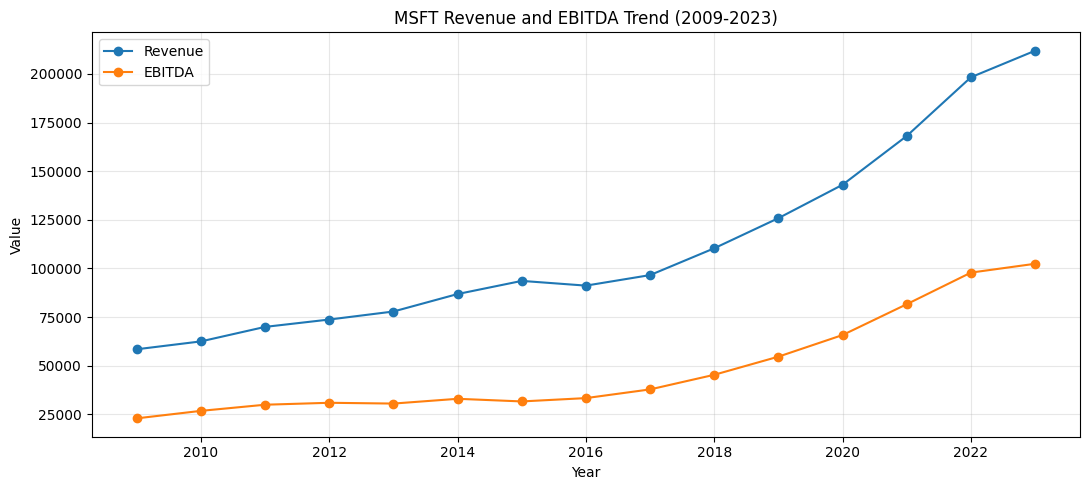

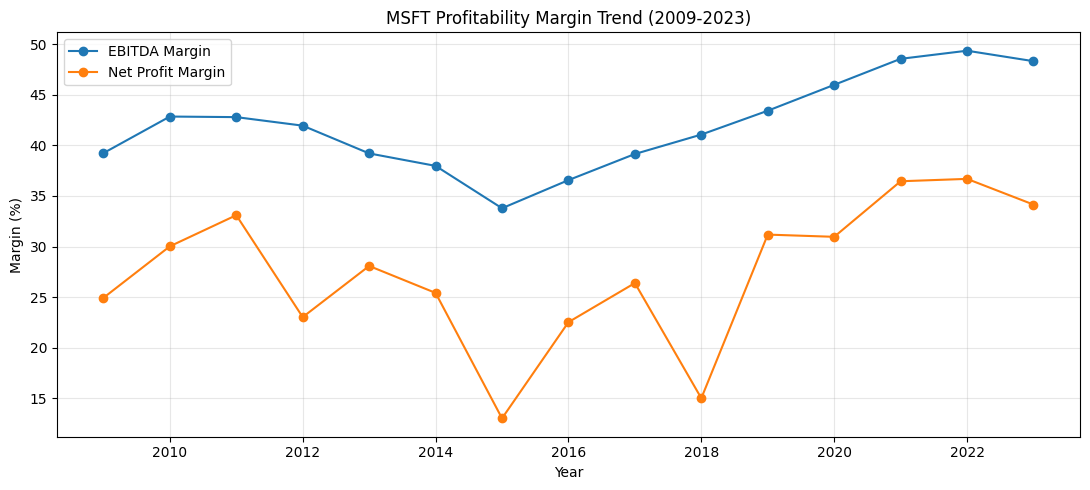

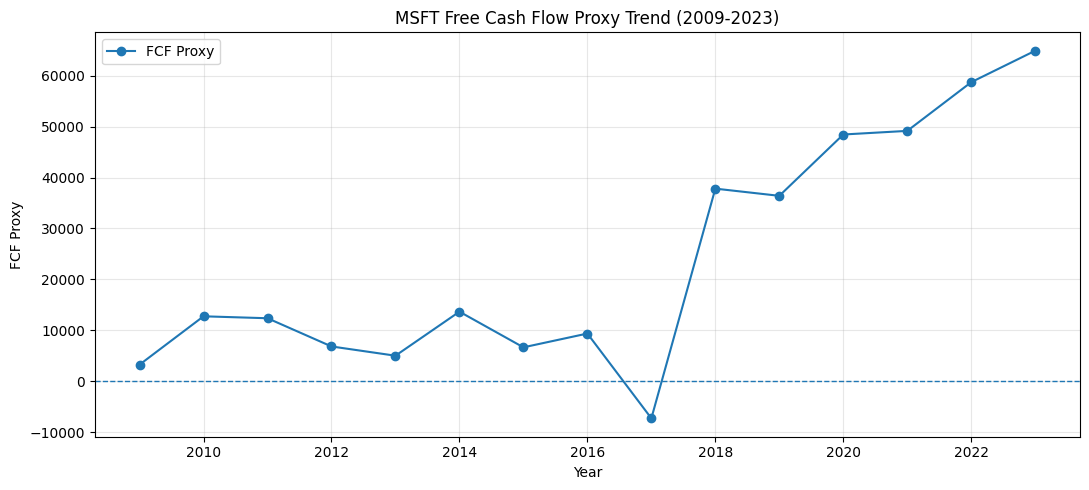

In [69]:
# Analyze MSFT's historical financial trends, risk indicators, and key investment signals, while generating validation charts.

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Define periods for comparison
# ------------------------------------------------------------

long_term = historical_msft.copy()
recent = historical_msft[historical_msft["Year"].between(2019, 2023)].copy()

# ------------------------------------------------------------
# 2. Calculate long-term and recent averages
# ------------------------------------------------------------

comparison_metrics = [
    "Revenue Growth",
    "EBITDA Growth",
    "EBITDA Margin",
    "Net Profit Margin",
    "ROE",
    "ROA",
    "ROI",
    "Current Ratio",
    "Debt/Equity Ratio",
    "FCF Margin"
]

period_comparison = pd.DataFrame({
    "Metric": comparison_metrics,
    "2009-2023 Average": [
        long_term[m].mean() for m in comparison_metrics
    ],
    "2019-2023 Average": [
        recent[m].mean() for m in comparison_metrics
    ]
})

period_comparison["Recent vs Historical Change"] = (
    period_comparison["2019-2023 Average"]
    - period_comparison["2009-2023 Average"]
)

period_comparison = period_comparison.round(2)

# ------------------------------------------------------------
# 3. Identify important historical extremes
# ------------------------------------------------------------

extreme_years = pd.DataFrame({
    "Metric": [
        "Highest Revenue Growth",
        "Lowest Revenue Growth",
        "Highest EBITDA Margin",
        "Lowest EBITDA Margin",
        "Highest Net Profit Margin",
        "Lowest Net Profit Margin",
        "Highest ROE",
        "Lowest ROE",
        "Highest FCF Margin",
        "Lowest FCF Margin",
        "Highest Debt/Equity",
        "Lowest Current Ratio"
    ],
    "Year": [
        historical_msft.loc[historical_msft["Revenue Growth"].idxmax(), "Year"],
        historical_msft.loc[historical_msft["Revenue Growth"].idxmin(), "Year"],
        historical_msft.loc[historical_msft["EBITDA Margin"].idxmax(), "Year"],
        historical_msft.loc[historical_msft["EBITDA Margin"].idxmin(), "Year"],
        historical_msft.loc[historical_msft["Net Profit Margin"].idxmax(), "Year"],
        historical_msft.loc[historical_msft["Net Profit Margin"].idxmin(), "Year"],
        historical_msft.loc[historical_msft["ROE"].idxmax(), "Year"],
        historical_msft.loc[historical_msft["ROE"].idxmin(), "Year"],
        historical_msft.loc[historical_msft["FCF Margin"].idxmax(), "Year"],
        historical_msft.loc[historical_msft["FCF Margin"].idxmin(), "Year"],
        historical_msft.loc[historical_msft["Debt/Equity Ratio"].idxmax(), "Year"],
        historical_msft.loc[historical_msft["Current Ratio"].idxmin(), "Year"]
    ],
    "Value": [
        historical_msft["Revenue Growth"].max(),
        historical_msft["Revenue Growth"].min(),
        historical_msft["EBITDA Margin"].max(),
        historical_msft["EBITDA Margin"].min(),
        historical_msft["Net Profit Margin"].max(),
        historical_msft["Net Profit Margin"].min(),
        historical_msft["ROE"].max(),
        historical_msft["ROE"].min(),
        historical_msft["FCF Margin"].max(),
        historical_msft["FCF Margin"].min(),
        historical_msft["Debt/Equity Ratio"].max(),
        historical_msft["Current Ratio"].min()
    ]
}).round(2)

# ------------------------------------------------------------
# 4. Identify years requiring special interpretation
# ------------------------------------------------------------

risk_flags = historical_msft[
    (historical_msft["FCF_Proxy"] < 0)
    | (historical_msft["Revenue Growth"] < 0)
    | (historical_msft["Net Profit Margin"] < 20)
    | (historical_msft["Debt/Equity Ratio"] > 0.75)
].copy()

risk_columns = [
    "Year",
    "Revenue Growth",
    "Net Profit Margin",
    "Debt/Equity Ratio",
    "Current Ratio",
    "FCF_Proxy",
    "FCF Margin"
]

risk_flags = risk_flags[risk_columns].round(2)

# ------------------------------------------------------------
# 5. Create management-level investment indicators
# ------------------------------------------------------------

investment_summary = pd.DataFrame({
    "Indicator": [
        "Recent Revenue CAGR (2018-2023)",
        "Recent EBITDA CAGR (2018-2023)",
        "Recent Net Income CAGR (2018-2023)",
        "Recent Operating Cash Flow CAGR (2018-2023)",
        "Recent FCF Proxy CAGR (2018-2023)",
        "Recent Average EBITDA Margin",
        "Recent Average Net Profit Margin",
        "Recent Average ROE",
        "Recent Average ROA",
        "Recent Average ROI",
        "Recent Average FCF Margin",
        "2023 Current Ratio",
        "2023 Debt/Equity Ratio"
    ],
    "Value": [
        recent_cagr_metrics["Revenue"],
        recent_cagr_metrics["EBITDA"],
        recent_cagr_metrics["Net Income"],
        recent_cagr_metrics["Cash Flow from Operating"],
        recent_cagr_metrics["FCF_Proxy"],
        recent["EBITDA Margin"].mean(),
        recent["Net Profit Margin"].mean(),
        recent["ROE"].mean(),
        recent["ROA"].mean(),
        recent["ROI"].mean(),
        recent["FCF Margin"].mean(),
        historical_msft.loc[historical_msft["Year"] == 2023, "Current Ratio"].iloc[0],
        historical_msft.loc[historical_msft["Year"] == 2023, "Debt/Equity Ratio"].iloc[0]
    ]
})

investment_summary["Value"] = investment_summary["Value"].round(2)

# ------------------------------------------------------------
# 6. Display analytical tables
# ------------------------------------------------------------

print("========== LONG-TERM VS RECENT PERFORMANCE ==========")
display(period_comparison)

print("\n========== HISTORICAL EXTREMES ==========")
display(extreme_years)

print("\n========== YEARS REQUIRING SPECIAL INTERPRETATION ==========")
display(risk_flags)

print("\n========== INVESTMENT-ORIENTED SUMMARY ==========")
display(investment_summary)

# ------------------------------------------------------------
# 7. Visualization 1 — Revenue and EBITDA trend
# ------------------------------------------------------------

plt.figure(figsize=(11, 5))
plt.plot(
    historical_msft["Year"],
    historical_msft["Revenue"],
    marker="o",
    label="Revenue"
)
plt.plot(
    historical_msft["Year"],
    historical_msft["EBITDA"],
    marker="o",
    label="EBITDA"
)

plt.title("MSFT Revenue and EBITDA Trend (2009-2023)")
plt.xlabel("Year")
plt.ylabel("Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Visualization 2 — Profitability margin trend
# ------------------------------------------------------------

plt.figure(figsize=(11, 5))
plt.plot(
    historical_msft["Year"],
    historical_msft["EBITDA Margin"],
    marker="o",
    label="EBITDA Margin"
)
plt.plot(
    historical_msft["Year"],
    historical_msft["Net Profit Margin"],
    marker="o",
    label="Net Profit Margin"
)

plt.title("MSFT Profitability Margin Trend (2009-2023)")
plt.xlabel("Year")
plt.ylabel("Margin (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Visualization 3 — FCF trend
# ------------------------------------------------------------

plt.figure(figsize=(11, 5))
plt.plot(
    historical_msft["Year"],
    historical_msft["FCF_Proxy"],
    marker="o",
    label="FCF Proxy"
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("MSFT Free Cash Flow Proxy Trend (2009-2023)")
plt.xlabel("Year")
plt.ylabel("FCF Proxy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [70]:
# Consolidate MSFT's historical evidence into forecast-relevant indicators and document the financial assumptions for the next modeling stage.

# ------------------------------------------------------------
# 1. Calculate recent trend indicators
# ------------------------------------------------------------

forecast_input_metrics = pd.DataFrame({
    "Metric": [
        "Revenue Growth",
        "EBITDA Margin",
        "Net Profit Margin",
        "Operating Cash Flow Margin",
        "FCF Margin",
        "ROE",
        "ROA",
        "ROI",
        "Current Ratio",
        "Debt/Equity Ratio"
    ],
    "Long-Term Average": [
        historical_msft["Revenue Growth"].mean(),
        historical_msft["EBITDA Margin"].mean(),
        historical_msft["Net Profit Margin"].mean(),
        (historical_msft["Cash Flow from Operating"] / historical_msft["Revenue"] * 100).mean(),
        historical_msft["FCF Margin"].mean(),
        historical_msft["ROE"].mean(),
        historical_msft["ROA"].mean(),
        historical_msft["ROI"].mean(),
        historical_msft["Current Ratio"].mean(),
        historical_msft["Debt/Equity Ratio"].mean()
    ],
    "Recent Average (2019-2023)": [
        recent["Revenue Growth"].mean(),
        recent["EBITDA Margin"].mean(),
        recent["Net Profit Margin"].mean(),
        (recent["Cash Flow from Operating"] / recent["Revenue"] * 100).mean(),
        recent["FCF Margin"].mean(),
        recent["ROE"].mean(),
        recent["ROA"].mean(),
        recent["ROI"].mean(),
        recent["Current Ratio"].mean(),
        recent["Debt/Equity Ratio"].mean()
    ],
    "2023 Value": [
        historical_msft.loc[historical_msft["Year"] == 2023, "Revenue Growth"].iloc[0],
        historical_msft.loc[historical_msft["Year"] == 2023, "EBITDA Margin"].iloc[0],
        historical_msft.loc[historical_msft["Year"] == 2023, "Net Profit Margin"].iloc[0],
        (historical_msft.loc[historical_msft["Year"] == 2023, "Cash Flow from Operating"].iloc[0] /
         historical_msft.loc[historical_msft["Year"] == 2023, "Revenue"].iloc[0] * 100),
        historical_msft.loc[historical_msft["Year"] == 2023, "FCF Margin"].iloc[0],
        historical_msft.loc[historical_msft["Year"] == 2023, "ROE"].iloc[0],
        historical_msft.loc[historical_msft["Year"] == 2023, "ROA"].iloc[0],
        historical_msft.loc[historical_msft["Year"] == 2023, "ROI"].iloc[0],
        historical_msft.loc[historical_msft["Year"] == 2023, "Current Ratio"].iloc[0],
        historical_msft.loc[historical_msft["Year"] == 2023, "Debt/Equity Ratio"].iloc[0]
    ]
})

forecast_input_metrics = forecast_input_metrics.round(2)

# ------------------------------------------------------------
# 2. Classify the reliability of each metric for forecasting
# ------------------------------------------------------------

forecast_guidance = pd.DataFrame({
    "Metric": [
        "Revenue Growth",
        "EBITDA Margin",
        "Net Profit Margin",
        "Operating Cash Flow",
        "FCF",
        "Net Income Growth",
        "ROE / ROA / ROI",
        "Debt / Equity",
        "Current Ratio"
    ],
    "Forecast Role": [
        "Primary driver",
        "Primary driver",
        "Secondary validation",
        "Cash-generation driver",
        "Valuation driver",
        "Use cautiously",
        "Supporting risk/quality indicators",
        "Risk constraint",
        "Liquidity check"
    ],
    "Historical Evidence": [
        "Recent growth is stronger than long-term average",
        "Recent margin is materially above historical average",
        "Recent margin is strong but historically volatile",
        "Recent OCF CAGR is 14.82%",
        "Recent FCF margin is 30.46%; 2017 requires special treatment",
        "Highly volatile historical growth",
        "Recent returns are above long-term averages",
        "2023 leverage is low relative to historical peak",
        "Liquidity remains positive despite gradual decline"
    ]
})

# ------------------------------------------------------------
# 3. Create a compact historical investment assessment
# ------------------------------------------------------------

historical_assessment = pd.DataFrame({
    "Dimension": [
        "Growth",
        "Profitability",
        "Cash Generation",
        "Returns",
        "Liquidity",
        "Leverage",
        "Historical Risk"
    ],
    "Assessment": [
        "Strong",
        "Strong",
        "Strong with one abnormal historical year",
        "Strong",
        "Healthy",
        "Conservative in 2023",
        "Moderate; historical volatility exists"
    ],
    "Evidence": [
        "2018-2023 Revenue CAGR = 13.94%",
        "2019-2023 EBITDA Margin = 47.12%",
        "2019-2023 FCF Margin = 30.46%",
        "2019-2023 ROE = 39.54%",
        "2023 Current Ratio = 1.77",
        "2023 Debt/Equity = 0.23",
        "2015-2018 contained major profitability, growth and FCF volatility"
    ]
})

# ------------------------------------------------------------
# 4. Display final historical assessment
# ------------------------------------------------------------

print("========== FORECAST-RELEVANT HISTORICAL METRICS ==========")
display(forecast_input_metrics)

print("\n========== FORECAST GUIDANCE ==========")
display(forecast_guidance)

print("\n========== HISTORICAL INVESTMENT ASSESSMENT ==========")
display(historical_assessment)

# ------------------------------------------------------------
# 5. Print the key modeling conclusions
# ------------------------------------------------------------

print("\n========== MODELING CONCLUSIONS ==========")

print("1. Revenue growth will be the primary top-line forecasting driver.")
print("2. EBITDA margin will be a primary operating-profitability assumption.")
print("3. Net profit margin will be used mainly as a validation metric.")
print("4. Operating cash flow and FCF margin will drive cash-flow analysis.")
print("5. Historical Net Income Growth will NOT be extrapolated directly.")
print("6. Historical FCF Growth will NOT be used as a direct forecasting input.")
print("7. ROE, ROA and ROI will be used as supporting investment-quality indicators.")
print("8. Debt/Equity and Current Ratio will be retained as risk and balance-sheet checks.")
print("9. The 2017 negative FCF Proxy will be retained as a historical anomaly, not removed.")

========== FORECAST-RELEVANT HISTORICAL METRICS ==========


,Metric,Long-Term Average,Recent Average (2019-2023),2023 Value
0,Revenue Growth,9.77,14.01,6.88
1,EBITDA Margin,42.01,47.12,48.31
2,Net Profit Margin,27.40,33.89,34.15
3,Operating Cash Flow Margin,39.45,43.16,41.33
4,FCF Margin,18.11,30.46,30.63
5,ROE,32.43,39.54,35.09
6,ROA,14.83,16.85,17.56
7,ROI,24.59,28.65,29.15
8,Current Ratio,2.38,2.14,1.77
9,Debt/Equity Ratio,0.43,0.44,0.23



========== FORECAST GUIDANCE ==========


,Metric,Forecast Role,Historical Evidence
0,Revenue Growth,Primary driver,Recent growth is stronger than long-term average
1,EBITDA Margin,Primary driver,Recent margin is materially above historical a...
2,Net Profit Margin,Secondary validation,Recent margin is strong but historically volatile
3,Operating Cash Flow,Cash-generation driver,Recent OCF CAGR is 14.82%
4,FCF,Valuation driver,Recent FCF margin is 30.46%; 2017 requires spe...
5,Net Income Growth,Use cautiously,Highly volatile historical growth
6,ROE / ROA / ROI,Supporting risk/quality indicators,Recent returns are above long-term averages
7,Debt / Equity,Risk constraint,2023 leverage is low relative to historical peak
8,Current Ratio,Liquidity check,Liquidity remains positive despite gradual dec...



========== HISTORICAL INVESTMENT ASSESSMENT ==========


,Dimension,Assessment,Evidence
0,Growth,Strong,2018-2023 Revenue CAGR = 13.94%
1,Profitability,Strong,2019-2023 EBITDA Margin = 47.12%
2,Cash Generation,Strong with one abnormal historical year,2019-2023 FCF Margin = 30.46%
3,Returns,Strong,2019-2023 ROE = 39.54%
4,Liquidity,Healthy,2023 Current Ratio = 1.77
5,Leverage,Conservative in 2023,2023 Debt/Equity = 0.23
6,Historical Risk,Moderate; historical volatility exists,"2015-2018 contained major profitability, growt..."



========== MODELING CONCLUSIONS ==========
1. Revenue growth will be the primary top-line forecasting driver.
2. EBITDA margin will be a primary operating-profitability assumption.
3. Net profit margin will be used mainly as a validation metric.
4. Operating cash flow and FCF margin will drive cash-flow analysis.
5. Historical Net Income Growth will NOT be extrapolated directly.
6. Historical FCF Growth will NOT be used as a direct forecasting input.
7. ROE, ROA and ROI will be used as supporting investment-quality indicators.
8. Debt/Equity and Current Ratio will be retained as risk and balance-sheet checks.
9. The 2017 negative FCF Proxy will be retained as a historical anomaly, not removed.


In [71]:
# Build a five-year MSFT revenue forecast using a moderated growth path informed by historical performance.

# ------------------------------------------------------------
# 1. Define forecast horizon
# ------------------------------------------------------------

forecast_years = [2024, 2025, 2026, 2027, 2028]

# ------------------------------------------------------------
# 2. Define revenue-growth assumptions
# ------------------------------------------------------------
# These assumptions intentionally moderate from recent performance
# toward MSFT's long-term historical growth profile.

revenue_growth_assumptions = {
    2024: 10.00,
    2025: 10.00,
    2026: 9.50,
    2027: 9.00,
    2028: 8.50
}

# ------------------------------------------------------------
# 3. Retrieve the 2023 actual revenue
# ------------------------------------------------------------

base_revenue = historical_msft.loc[
    historical_msft["Year"] == 2023,
    "Revenue"
].iloc[0]

# ------------------------------------------------------------
# 4. Generate revenue forecast
# ------------------------------------------------------------

forecast_revenue = []

previous_revenue = base_revenue

for year in forecast_years:
    growth_rate = revenue_growth_assumptions[year]
    projected_revenue = previous_revenue * (1 + growth_rate / 100)

    forecast_revenue.append({
        "Year": year,
        "Revenue Growth Assumption (%)": growth_rate,
        "Projected Revenue": projected_revenue
    })

    previous_revenue = projected_revenue

forecast_revenue = pd.DataFrame(forecast_revenue)

# ------------------------------------------------------------
# 5. Display forecast
# ------------------------------------------------------------

forecast_revenue["Projected Revenue"] = forecast_revenue[
    "Projected Revenue"
].round(2)

display(forecast_revenue)

# ------------------------------------------------------------
# 6. Validate the forecast against the historical range
# ------------------------------------------------------------

forecast_revenue_cagr = (
    (
        forecast_revenue["Projected Revenue"].iloc[-1]
        / base_revenue
    ) ** (1 / len(forecast_years)) - 1
) * 100

print("\n2023 Actual Revenue:", round(base_revenue, 2))
print("2028 Projected Revenue:", round(forecast_revenue["Projected Revenue"].iloc[-1], 2))
print("2023-2028 Revenue CAGR:", round(forecast_revenue_cagr, 2), "%")

print("\nRevenue growth assumptions:")
for year, growth in revenue_growth_assumptions.items():
    print(f"{year}: {growth:.2f}%")

,Year,Revenue Growth Assumption (%),Projected Revenue
0,2024,10.0,233106.50
1,2025,10.0,256417.15
2,2026,9.5,280776.78
3,2027,9.0,306046.69
4,2028,8.5,332060.66



2023 Actual Revenue: 211915.0
2028 Projected Revenue: 332060.66
2023-2028 Revenue CAGR: 9.4 %

Revenue growth assumptions:
2024: 10.00%
2025: 10.00%
2026: 9.50%
2027: 9.00%
2028: 8.50%


In [72]:
# Build MSFT's 2024-2028 EBITDA, Net Income, Operating Cash Flow, and FCF forecasts using historically supported margin assumptions.

# ------------------------------------------------------------
# 1. Define forecast margin assumptions
# ------------------------------------------------------------
# These assumptions are anchored to recent historical averages
# and 2023 actual values, with modest normalization over time.

forecast_assumptions = pd.DataFrame({
    "Year": forecast_years,

    # EBITDA margin remains close to the recent historical level
    # but gradually normalizes from the 2023 level of 48.31%.
    "EBITDA Margin (%)": [48.00, 48.00, 47.75, 47.50, 47.25],

    # Net profit margin remains around the recent historical level
    # while allowing for modest normalization.
    "Net Profit Margin (%)": [34.00, 34.00, 33.75, 33.50, 33.25],

    # OCF margin is anchored around the recent 43.16% average
    # but kept slightly conservative relative to that average.
    "OCF Margin (%)": [42.50, 42.50, 42.25, 42.00, 41.75],

    # FCF margin is anchored around the recent 30.46% average
    # and kept broadly stable rather than extrapolating volatile FCF growth.
    "FCF Margin (%)": [30.50, 30.50, 30.25, 30.00, 30.00]
})

# ------------------------------------------------------------
# 2. Merge revenue forecast with operating assumptions
# ------------------------------------------------------------

financial_forecast = forecast_revenue.merge(
    forecast_assumptions,
    on="Year",
    how="left"
)

# ------------------------------------------------------------
# 3. Calculate EBITDA
# ------------------------------------------------------------

financial_forecast["Projected EBITDA"] = (
    financial_forecast["Projected Revenue"]
    * financial_forecast["EBITDA Margin (%)"]
    / 100
)

# ------------------------------------------------------------
# 4. Calculate Net Income
# ------------------------------------------------------------

financial_forecast["Projected Net Income"] = (
    financial_forecast["Projected Revenue"]
    * financial_forecast["Net Profit Margin (%)"]
    / 100
)

# ------------------------------------------------------------
# 5. Calculate Operating Cash Flow
# ------------------------------------------------------------

financial_forecast["Projected Operating Cash Flow"] = (
    financial_forecast["Projected Revenue"]
    * financial_forecast["OCF Margin (%)"]
    / 100
)

# ------------------------------------------------------------
# 6. Calculate FCF Proxy
# ------------------------------------------------------------

financial_forecast["Projected FCF"] = (
    financial_forecast["Projected Revenue"]
    * financial_forecast["FCF Margin (%)"]
    / 100
)

# ------------------------------------------------------------
# 7. Calculate year-over-year growth for forecasted metrics
# ------------------------------------------------------------

growth_metrics = [
    "Projected Revenue",
    "Projected EBITDA",
    "Projected Net Income",
    "Projected Operating Cash Flow",
    "Projected FCF"
]

for metric in growth_metrics:
    financial_forecast[f"{metric} Growth (%)"] = (
        financial_forecast[metric].pct_change() * 100
    )

# ------------------------------------------------------------
# 8. Round numerical values for presentation
# ------------------------------------------------------------

financial_forecast = financial_forecast.round(2)

# ------------------------------------------------------------
# 9. Display the complete forecast
# ------------------------------------------------------------

forecast_columns = [
    "Year",
    "Revenue Growth Assumption (%)",
    "Projected Revenue",
    "EBITDA Margin (%)",
    "Projected EBITDA",
    "Net Profit Margin (%)",
    "Projected Net Income",
    "OCF Margin (%)",
    "Projected Operating Cash Flow",
    "FCF Margin (%)",
    "Projected FCF"
]

print("========== MSFT BASE-CASE FINANCIAL FORECAST ==========")
display(financial_forecast[forecast_columns])

# ------------------------------------------------------------
# 10. Calculate forecast CAGRs
# ------------------------------------------------------------

forecast_cagr = {}

for metric in [
    "Projected Revenue",
    "Projected EBITDA",
    "Projected Net Income",
    "Projected Operating Cash Flow",
    "Projected FCF"
]:
    start_value = financial_forecast[metric].iloc[0]
    end_value = financial_forecast[metric].iloc[-1]

    cagr = (
        (end_value / start_value) ** (1 / (len(forecast_years) - 1)) - 1
    ) * 100

    forecast_cagr[metric] = cagr

forecast_cagr_table = pd.DataFrame(
    list(forecast_cagr.items()),
    columns=["Forecast Metric", "2024-2028 CAGR (%)"]
).round(2)

print("\n========== FORECAST GROWTH ==========")
display(forecast_cagr_table)

# ------------------------------------------------------------
# 11. Compare 2023 actual with 2028 forecast
# ------------------------------------------------------------

actual_2023 = historical_msft[
    historical_msft["Year"] == 2023
].iloc[0]

comparison_2023_2028 = pd.DataFrame({
    "Metric": [
        "Revenue",
        "EBITDA",
        "Net Income",
        "Operating Cash Flow",
        "FCF"
    ],
    "2023 Actual": [
        actual_2023["Revenue"],
        actual_2023["EBITDA"],
        actual_2023["Net Income"],
        actual_2023["Cash Flow from Operating"],
        actual_2023["FCF_Proxy"]
    ],
    "2028 Forecast": [
        financial_forecast["Projected Revenue"].iloc[-1],
        financial_forecast["Projected EBITDA"].iloc[-1],
        financial_forecast["Projected Net Income"].iloc[-1],
        financial_forecast["Projected Operating Cash Flow"].iloc[-1],
        financial_forecast["Projected FCF"].iloc[-1]
    ]
})

comparison_2023_2028["Absolute Change"] = (
    comparison_2023_2028["2028 Forecast"]
    - comparison_2023_2028["2023 Actual"]
)

comparison_2023_2028["Growth (%)"] = (
    comparison_2023_2028["2028 Forecast"]
    / comparison_2023_2028["2023 Actual"]
    - 1
) * 100

comparison_2023_2028 = comparison_2023_2028.round(2)

print("\n========== 2023 ACTUAL VS 2028 FORECAST ==========")
display(comparison_2023_2028)

========== MSFT BASE-CASE FINANCIAL FORECAST ==========


,Year,Revenue Growth Assumption (%),Projected Revenue,EBITDA Margin (%),Projected EBITDA,Net Profit Margin (%),Projected Net Income,OCF Margin (%),Projected Operating Cash Flow,FCF Margin (%),Projected FCF
0,2024,10.0,233106.50,48.00,111891.12,34.00,79256.21,42.50,99070.26,30.50,71097.48
1,2025,10.0,256417.15,48.00,123080.23,34.00,87181.83,42.50,108977.29,30.50,78207.23
2,2026,9.5,280776.78,47.75,134070.91,33.75,94762.16,42.25,118628.19,30.25,84934.98
3,2027,9.0,306046.69,47.50,145372.18,33.50,102525.64,42.00,128539.61,30.00,91814.01
4,2028,8.5,332060.66,47.25,156898.66,33.25,110410.17,41.75,138635.33,30.00,99618.20



========== FORECAST GROWTH ==========


,Forecast Metric,2024-2028 CAGR (%)
0,Projected Revenue,9.25
1,Projected EBITDA,8.82
2,Projected Net Income,8.64
3,Projected Operating Cash Flow,8.76
4,Projected FCF,8.80



========== 2023 ACTUAL VS 2028 FORECAST ==========


,Metric,2023 Actual,2028 Forecast,Absolute Change,Growth (%)
0,Revenue,211915.0,332060.66,120145.66,56.70
1,EBITDA,102384.0,156898.66,54514.66,53.25
2,Net Income,72361.0,110410.17,38049.17,52.58
3,Operating Cash Flow,87582.0,138635.33,51053.33,58.29
4,FCF,64902.0,99618.20,34716.20,53.49


In [73]:
# Build Bear, Base, and Bull financial scenarios for MSFT using different revenue-growth and profitability assumptions.

# ------------------------------------------------------------
# 1. Define scenario assumptions
# ------------------------------------------------------------

scenario_assumptions = {
    "Bear": {
        "Revenue Growth": [7.0, 7.0, 6.5, 6.0, 5.5],
        "EBITDA Margin": [46.0, 45.75, 45.5, 45.25, 45.0],
        "Net Profit Margin": [32.0, 31.75, 31.5, 31.25, 31.0],
        "OCF Margin": [40.0, 39.75, 39.5, 39.25, 39.0],
        "FCF Margin": [27.0, 27.0, 26.75, 26.5, 26.5]
    },

    "Base": {
        "Revenue Growth": [10.0, 10.0, 9.5, 9.0, 8.5],
        "EBITDA Margin": [48.0, 48.0, 47.75, 47.5, 47.25],
        "Net Profit Margin": [34.0, 34.0, 33.75, 33.5, 33.25],
        "OCF Margin": [42.5, 42.5, 42.25, 42.0, 41.75],
        "FCF Margin": [30.5, 30.5, 30.25, 30.0, 30.0]
    },

    "Bull": {
        "Revenue Growth": [12.0, 12.0, 11.5, 11.0, 10.5],
        "EBITDA Margin": [49.0, 49.25, 49.25, 49.0, 48.75],
        "Net Profit Margin": [35.0, 35.25, 35.25, 35.0, 34.75],
        "OCF Margin": [44.0, 44.25, 44.25, 44.0, 43.75],
        "FCF Margin": [32.0, 32.25, 32.25, 32.0, 31.75]
    }
}

# ------------------------------------------------------------
# 2. Generate scenario forecasts
# ------------------------------------------------------------

scenario_results = []

for scenario, assumptions in scenario_assumptions.items():

    previous_revenue = base_revenue

    for i, year in enumerate(forecast_years):

        revenue_growth = assumptions["Revenue Growth"][i]
        ebitda_margin = assumptions["EBITDA Margin"][i]
        net_margin = assumptions["Net Profit Margin"][i]
        ocf_margin = assumptions["OCF Margin"][i]
        fcf_margin = assumptions["FCF Margin"][i]

        projected_revenue = previous_revenue * (1 + revenue_growth / 100)

        projected_ebitda = projected_revenue * ebitda_margin / 100
        projected_net_income = projected_revenue * net_margin / 100
        projected_ocf = projected_revenue * ocf_margin / 100
        projected_fcf = projected_revenue * fcf_margin / 100

        scenario_results.append({
            "Scenario": scenario,
            "Year": year,
            "Revenue Growth (%)": revenue_growth,
            "Revenue": projected_revenue,
            "EBITDA Margin (%)": ebitda_margin,
            "EBITDA": projected_ebitda,
            "Net Profit Margin (%)": net_margin,
            "Net Income": projected_net_income,
            "OCF Margin (%)": ocf_margin,
            "Operating Cash Flow": projected_ocf,
            "FCF Margin (%)": fcf_margin,
            "FCF": projected_fcf
        })

        previous_revenue = projected_revenue

scenario_forecast = pd.DataFrame(scenario_results)

# ------------------------------------------------------------
# 3. Extract 2028 scenario outcomes
# ------------------------------------------------------------

scenario_2028 = scenario_forecast[
    scenario_forecast["Year"] == 2028
][
    [
        "Scenario",
        "Revenue",
        "EBITDA",
        "Net Income",
        "Operating Cash Flow",
        "FCF"
    ]
].copy()

scenario_2028 = scenario_2028.round(2)

print("========== 2028 SCENARIO OUTCOMES ==========")
display(scenario_2028)

# ------------------------------------------------------------
# 4. Calculate 2023-2028 revenue CAGR for each scenario
# ------------------------------------------------------------

scenario_cagr = []

for scenario in scenario_forecast["Scenario"].unique():

    scenario_data = scenario_forecast[
        scenario_forecast["Scenario"] == scenario
    ]

    ending_revenue = scenario_data[
        scenario_data["Year"] == 2028
    ]["Revenue"].iloc[0]

    cagr = (
        (ending_revenue / base_revenue) ** (1 / 5) - 1
    ) * 100

    ending_fcf = scenario_data[
        scenario_data["Year"] == 2028
    ]["FCF"].iloc[0]

    scenario_cagr.append({
        "Scenario": scenario,
        "2023-2028 Revenue CAGR (%)": cagr,
        "2028 FCF": ending_fcf
    })

scenario_cagr = pd.DataFrame(scenario_cagr).round(2)

print("\n========== SCENARIO GROWTH ==========")
display(scenario_cagr)

# ------------------------------------------------------------
# 5. Calculate the range between Bear and Bull outcomes
# ------------------------------------------------------------

scenario_range = pd.DataFrame({
    "Metric": [
        "2028 Revenue",
        "2028 EBITDA",
        "2028 Net Income",
        "2028 Operating Cash Flow",
        "2028 FCF"
    ],
    "Bear": [
        scenario_2028.loc[scenario_2028["Scenario"] == "Bear", "Revenue"].iloc[0],
        scenario_2028.loc[scenario_2028["Scenario"] == "Bear", "EBITDA"].iloc[0],
        scenario_2028.loc[scenario_2028["Scenario"] == "Bear", "Net Income"].iloc[0],
        scenario_2028.loc[scenario_2028["Scenario"] == "Bear", "Operating Cash Flow"].iloc[0],
        scenario_2028.loc[scenario_2028["Scenario"] == "Bear", "FCF"].iloc[0]
    ],
    "Base": [
        scenario_2028.loc[scenario_2028["Scenario"] == "Base", "Revenue"].iloc[0],
        scenario_2028.loc[scenario_2028["Scenario"] == "Base", "EBITDA"].iloc[0],
        scenario_2028.loc[scenario_2028["Scenario"] == "Base", "Net Income"].iloc[0],
        scenario_2028.loc[scenario_2028["Scenario"] == "Base", "Operating Cash Flow"].iloc[0],
        scenario_2028.loc[scenario_2028["Scenario"] == "Base", "FCF"].iloc[0]
    ],
    "Bull": [
        scenario_2028.loc[scenario_2028["Scenario"] == "Bull", "Revenue"].iloc[0],
        scenario_2028.loc[scenario_2028["Scenario"] == "Bull", "EBITDA"].iloc[0],
        scenario_2028.loc[scenario_2028["Scenario"] == "Bull", "Net Income"].iloc[0],
        scenario_2028.loc[scenario_2028["Scenario"] == "Bull", "Operating Cash Flow"].iloc[0],
        scenario_2028.loc[scenario_2028["Scenario"] == "Bull", "FCF"].iloc[0]
    ]
})

scenario_range = scenario_range.round(2)

print("\n========== BEAR / BASE / BULL RANGE ==========")
display(scenario_range)

========== 2028 SCENARIO OUTCOMES ==========


,Scenario,Revenue,EBITDA,Net Income,Operating Cash Flow,FCF
4,Bear,288959.64,130031.84,89577.49,112694.26,76574.30
9,Base,332060.66,156898.66,110410.17,138635.32,99618.20
14,Bull,363544.74,177228.06,126331.80,159050.82,115425.46



========== SCENARIO GROWTH ==========


,Scenario,2023-2028 Revenue CAGR (%),2028 FCF
0,Bear,6.4,76574.30
1,Base,9.4,99618.20
2,Bull,11.4,115425.46



========== BEAR / BASE / BULL RANGE ==========


,Metric,Bear,Base,Bull
0,2028 Revenue,288959.64,332060.66,363544.74
1,2028 EBITDA,130031.84,156898.66,177228.06
2,2028 Net Income,89577.49,110410.17,126331.80
3,2028 Operating Cash Flow,112694.26,138635.32,159050.82
4,2028 FCF,76574.30,99618.20,115425.46


In [74]:
# Calculate indicative DCF values for Bear, Base, and Bull scenarios and perform a WACC/terminal-growth sensitivity analysis.

# ------------------------------------------------------------
# 1. Define DCF assumptions
# ------------------------------------------------------------

base_wacc = 0.09
base_terminal_growth = 0.03

# ------------------------------------------------------------
# 2. Create a function to calculate DCF enterprise value
# ------------------------------------------------------------

def calculate_dcf(fcf_values, wacc, terminal_growth):
    """
    Calculate the present value of forecast FCFs plus terminal value.
    FCF is treated as a proxy for valuation cash flow.
    """

    forecast_pv = 0

    for period, fcf in enumerate(fcf_values, start=1):
        forecast_pv += fcf / ((1 + wacc) ** period)

    terminal_fcf = fcf_values[-1] * (1 + terminal_growth)

    terminal_value = (
        terminal_fcf
        / (wacc - terminal_growth)
    )

    terminal_pv = (
        terminal_value
        / ((1 + wacc) ** len(fcf_values))
    )

    enterprise_value = forecast_pv + terminal_pv

    return forecast_pv, terminal_value, terminal_pv, enterprise_value

# ------------------------------------------------------------
# 3. Calculate DCF valuation for each scenario
# ------------------------------------------------------------

dcf_results = []

for scenario in ["Bear", "Base", "Bull"]:

    scenario_data = scenario_forecast[
        scenario_forecast["Scenario"] == scenario
    ].sort_values("Year")

    fcf_values = scenario_data["FCF"].tolist()

    forecast_pv, terminal_value, terminal_pv, enterprise_value = calculate_dcf(
        fcf_values,
        base_wacc,
        base_terminal_growth
    )

    dcf_results.append({
        "Scenario": scenario,
        "PV of 2024-2028 FCF": forecast_pv,
        "Terminal Value": terminal_value,
        "PV of Terminal Value": terminal_pv,
        "Indicative Enterprise Value": enterprise_value
    })

dcf_results = pd.DataFrame(dcf_results).round(2)

print("========== INDICATIVE DCF VALUATION ==========")
display(dcf_results)

# ------------------------------------------------------------
# 4. Calculate terminal value contribution
# ------------------------------------------------------------

dcf_results["Terminal Value % of EV"] = (
    dcf_results["PV of Terminal Value"]
    / dcf_results["Indicative Enterprise Value"]
    * 100
).round(2)

print("\n========== DCF VALUE COMPOSITION ==========")
display(
    dcf_results[
        [
            "Scenario",
            "PV of 2024-2028 FCF",
            "PV of Terminal Value",
            "Terminal Value % of EV"
        ]
    ]
)

# ------------------------------------------------------------
# 5. Perform WACC / terminal-growth sensitivity analysis
# ------------------------------------------------------------

wacc_values = [0.08, 0.09, 0.10, 0.11]
terminal_growth_values = [0.02, 0.03, 0.04]

base_scenario_data = scenario_forecast[
    scenario_forecast["Scenario"] == "Base"
].sort_values("Year")

base_fcf_values = base_scenario_data["FCF"].tolist()

sensitivity_rows = []

for wacc in wacc_values:

    row = {"WACC": f"{wacc * 100:.0f}%"}

    for terminal_growth in terminal_growth_values:

        _, _, _, enterprise_value = calculate_dcf(
            base_fcf_values,
            wacc,
            terminal_growth
        )

        row[
            f"Terminal Growth {terminal_growth * 100:.0f}%"
        ] = round(enterprise_value, 2)

    sensitivity_rows.append(row)

dcf_sensitivity = pd.DataFrame(sensitivity_rows)

print("\n========== BASE-CASE DCF SENSITIVITY ==========")
display(dcf_sensitivity)

# ------------------------------------------------------------
# 6. Compare DCF enterprise values across scenarios
# ------------------------------------------------------------

scenario_valuation_summary = dcf_results[
    [
        "Scenario",
        "Indicative Enterprise Value",
        "Terminal Value % of EV"
    ]
].copy()

scenario_valuation_summary = scenario_valuation_summary.round(2)

print("\n========== SCENARIO VALUATION RANGE ==========")
display(scenario_valuation_summary)

# ------------------------------------------------------------
# 7. Display the assumptions used
# ------------------------------------------------------------

print("\n========== DCF ASSUMPTIONS ==========")
print(f"Forecast period: 2024-2028")
print(f"Base WACC: {base_wacc * 100:.1f}%")
print(f"Base terminal growth: {base_terminal_growth * 100:.1f}%")
print("Cash-flow measure: Dataset FCF Proxy")
print("Valuation type: Indicative DCF / Enterprise Value")

========== INDICATIVE DCF VALUATION ==========


,Scenario,PV of 2024-2028 FCF,Terminal Value,PV of Terminal Value,Indicative Enterprise Value
0,Bear,265864.15,1314525.56,854351.42,1120215.57
1,Base,326426.25,1710112.39,1111455.72,1437881.96
2,Bull,365248.42,1981470.32,1287819.75,1653068.17



========== DCF VALUE COMPOSITION ==========


,Scenario,PV of 2024-2028 FCF,PV of Terminal Value,Terminal Value % of EV
0,Bear,265864.15,854351.42,76.27
1,Base,326426.25,1111455.72,77.30
2,Bull,365248.42,1287819.75,77.90



========== BASE-CASE DCF SENSITIVITY ==========


,WACC,Terminal Growth 2%,Terminal Growth 3%,Terminal Growth 4%
0,8%,1488163.74,1732238.23,2098349.98
1,9%,1269853.29,1437881.96,1673122.10
2,10%,1106298.37,1227799.39,1389800.74
3,11%,979239.78,1070380.88,1187562.30



========== SCENARIO VALUATION RANGE ==========


,Scenario,Indicative Enterprise Value,Terminal Value % of EV
0,Bear,1120215.57,76.27
1,Base,1437881.96,77.30
2,Bull,1653068.17,77.90



========== DCF ASSUMPTIONS ==========
Forecast period: 2024-2028
Base WACC: 9.0%
Base terminal growth: 3.0%
Cash-flow measure: Dataset FCF Proxy
Valuation type: Indicative DCF / Enterprise Value


In [75]:
# Compare the DCF valuation range with MSFT's 2023 market capitalization and construct the final investment decision framework.

# ------------------------------------------------------------
# 1. Retrieve MSFT's 2023 market capitalization
# ------------------------------------------------------------

market_cap_2023 = historical_msft.loc[
    historical_msft["Year"] == 2023,
    "Market Cap(in B USD)"
].iloc[0]

# ------------------------------------------------------------
# 2. Create valuation comparison
# ------------------------------------------------------------

valuation_comparison = dcf_results[
    [
        "Scenario",
        "Indicative Enterprise Value"
    ]
].copy()

valuation_comparison["2023 Market Cap"] = market_cap_2023

valuation_comparison["DCF vs Market Cap (%)"] = (
    (
        valuation_comparison["Indicative Enterprise Value"]
        / valuation_comparison["2023 Market Cap"]
    ) - 1
) * 100

valuation_comparison["Valuation Multiple vs Market Cap"] = (
    valuation_comparison["Indicative Enterprise Value"]
    / valuation_comparison["2023 Market Cap"]
)

valuation_comparison = valuation_comparison.round(2)

print("========== DCF VS 2023 MARKET CAPITALIZATION ==========")
display(valuation_comparison)

# ------------------------------------------------------------
# 3. Calculate the base-case valuation gap
# ------------------------------------------------------------

base_ev = valuation_comparison.loc[
    valuation_comparison["Scenario"] == "Base",
    "Indicative Enterprise Value"
].iloc[0]

base_valuation_gap = (
    (base_ev / market_cap_2023) - 1
) * 100

print("\n2023 Market Capitalization:", round(market_cap_2023, 2))
print("Base-Case Indicative DCF EV:", round(base_ev, 2))
print("Base-Case DCF vs Market Cap:", round(base_valuation_gap, 2), "%")

# ------------------------------------------------------------
# 4. Create valuation sensitivity interpretation
# ------------------------------------------------------------

sensitivity_summary = pd.DataFrame({
    "Condition": [
        "Most Conservative DCF Sensitivity",
        "Base DCF",
        "Most Optimistic DCF Sensitivity"
    ],
    "WACC": [
        "11%",
        "9%",
        "8%"
    ],
    "Terminal Growth": [
        "2%",
        "3%",
        "4%"
    ],
    "Indicative EV": [
        dcf_sensitivity.iloc[-1]["Terminal Growth 2%"],
        dcf_sensitivity.loc[
            dcf_sensitivity["WACC"] == "9%",
            "Terminal Growth 3%"
        ].iloc[0],
        dcf_sensitivity.iloc[0]["Terminal Growth 4%"]
    ]
})

sensitivity_summary = sensitivity_summary.round(2)

print("\n========== DCF SENSITIVITY BOUNDARIES ==========")
display(sensitivity_summary)

# ------------------------------------------------------------
# 5. Construct final investment assessment
# ------------------------------------------------------------

investment_decision = pd.DataFrame({
    "Decision Dimension": [
        "Historical Growth",
        "Historical Profitability",
        "Cash Generation",
        "Returns",
        "Liquidity",
        "Leverage",
        "Forecast Growth",
        "Forecast Cash Generation",
        "DCF Base Case",
        "DCF Sensitivity",
        "Overall Investment View"
    ],
    "Assessment": [
        "Strong",
        "Strong",
        "Strong",
        "Strong",
        "Healthy",
        "Conservative",
        "Moderate-to-Strong",
        "Strong",
        "Potentially Attractive",
        "Highly Sensitive",
        "Requires Market-Price Confirmation"
    ],
    "Evidence": [
        "2018-2023 Revenue CAGR = 13.94%",
        "2019-2023 EBITDA Margin = 47.12%",
        "2019-2023 FCF Margin = 30.46%",
        "2019-2023 ROE = 39.54%",
        "2023 Current Ratio = 1.77",
        "2023 Debt/Equity = 0.23",
        "Base case Revenue CAGR = 9.4%",
        "2028 Base FCF = 99,618",
        "Base DCF EV = 1.438T",
        "Terminal value represents 77.3% of Base EV",
        "DCF should be compared with actual market price/equity value before issuing Buy/Hold/Sell"
    ]
})

print("\n========== FINAL INVESTMENT ASSESSMENT ==========")
display(investment_decision)

# ------------------------------------------------------------
# 6. State the valuation methodology limitation
# ------------------------------------------------------------

print("\n========== METHODOLOGY LIMITATION ==========")
print("The dataset provides Market Cap but does not provide a clean standalone")
print("Cash and Debt bridge required to convert Enterprise Value into Equity Value.")
print("Therefore, the DCF is presented as an INDICATIVE ENTERPRISE VALUE.")
print("A definitive Buy/Hold/Sell conclusion requires comparison with the")
print("appropriate equity-value / market-price benchmark.")

========== DCF VS 2023 MARKET CAPITALIZATION ==========


,Scenario,Indicative Enterprise Value,2023 Market Cap,DCF vs Market Cap (%),Valuation Multiple vs Market Cap
0,Bear,1120215.57,2451.23,45600.14,457.00
1,Base,1437881.96,2451.23,58559.61,586.60
2,Bull,1653068.17,2451.23,67338.31,674.38



2023 Market Capitalization: 2451.23
Base-Case Indicative DCF EV: 1437881.96
Base-Case DCF vs Market Cap: 58559.61 %

========== DCF SENSITIVITY BOUNDARIES ==========


,Condition,WACC,Terminal Growth,Indicative EV
0,Most Conservative DCF Sensitivity,11%,2%,979239.78
1,Base DCF,9%,3%,1437881.96
2,Most Optimistic DCF Sensitivity,8%,4%,2098349.98



========== FINAL INVESTMENT ASSESSMENT ==========


,Decision Dimension,Assessment,Evidence
0,Historical Growth,Strong,2018-2023 Revenue CAGR = 13.94%
1,Historical Profitability,Strong,2019-2023 EBITDA Margin = 47.12%
2,Cash Generation,Strong,2019-2023 FCF Margin = 30.46%
3,Returns,Strong,2019-2023 ROE = 39.54%
4,Liquidity,Healthy,2023 Current Ratio = 1.77
5,Leverage,Conservative,2023 Debt/Equity = 0.23
6,Forecast Growth,Moderate-to-Strong,Base case Revenue CAGR = 9.4%
7,Forecast Cash Generation,Strong,"2028 Base FCF = 99,618"
8,DCF Base Case,Potentially Attractive,Base DCF EV = 1.438T
9,DCF Sensitivity,Highly Sensitive,Terminal value represents 77.3% of Base EV



========== METHODOLOGY LIMITATION ==========
The dataset provides Market Cap but does not provide a clean standalone
Cash and Debt bridge required to convert Enterprise Value into Equity Value.
Therefore, the DCF is presented as an INDICATIVE ENTERPRISE VALUE.
A definitive Buy/Hold/Sell conclusion requires comparison with the
appropriate equity-value / market-price benchmark.


In [78]:
# Build the final project integration tables using the actual column names created by the forecasting model.

print("=" * 70)
print("CHECKING FORECAST COLUMNS")
print("=" * 70)

print("\nFinancial forecast columns:")
print(financial_forecast.columns.tolist())

print("\nScenario forecast columns:")
print(scenario_forecast.columns.tolist())


# ============================================================
# 1. HISTORICAL PERFORMANCE TABLE
# ============================================================

historical_output = historical_msft[
    [
        "Year",
        "Company",
        "Revenue",
        "Revenue Growth",
        "EBITDA",
        "EBITDA Margin",
        "Net Income",
        "Net Profit Margin",
        "Cash Flow from Operating",
        "FCF_Proxy",
        "FCF Margin",
        "ROE",
        "ROA",
        "ROI",
        "Current Ratio",
        "Debt/Equity Ratio",
        "Number of Employees"
    ]
].copy()

historical_output = historical_output.round(2)


# ============================================================
# 2. BASE FORECAST TABLE
# ============================================================

forecast_output = financial_forecast.copy()

forecast_output.insert(0, "Company", "MSFT")
forecast_output["Forecast Type"] = "Base"

forecast_output = forecast_output.rename(columns={
    "Projected Revenue Growth (%)": "Revenue Growth",
    "EBITDA Margin (%)": "EBITDA Margin",
    "Net Profit Margin (%)": "Net Profit Margin",
    "OCF Margin (%)": "OCF Margin",
    "FCF Margin (%)": "FCF Margin"
})

print("\nForecast columns after standardization:")
print(forecast_output.columns.tolist())


# ============================================================
# 3. SCENARIO FORECAST TABLE
# ============================================================

scenario_output = scenario_forecast.copy()

scenario_output.insert(0, "Company", "MSFT")

scenario_output = scenario_output.rename(columns={
    "Projected Revenue Growth (%)": "Revenue Growth",
    "EBITDA Margin (%)": "EBITDA Margin",
    "Net Profit Margin (%)": "Net Profit Margin",
    "OCF Margin (%)": "OCF Margin",
    "FCF Margin (%)": "FCF Margin"
})

print("\nScenario columns after standardization:")
print(scenario_output.columns.tolist())


# ============================================================
# 4. DCF TABLE
# ============================================================

dcf_output = dcf_results.copy()

dcf_output.insert(0, "Company", "MSFT")

dcf_output = dcf_output.round(2)


# ============================================================
# 5. DCF SENSITIVITY TABLE
# ============================================================

dcf_sensitivity_output = dcf_sensitivity.copy()

dcf_sensitivity_output.insert(0, "Company", "MSFT")

dcf_sensitivity_output = dcf_sensitivity_output.round(2)


# ============================================================
# 6. RISK & QUALITY ASSESSMENT
# ============================================================

risk_output = pd.DataFrame({
    "Company": ["MSFT"] * 10,
    "Risk / Quality Dimension": [
        "Historical Growth",
        "Historical Profitability",
        "Cash Generation",
        "Returns",
        "Liquidity",
        "Leverage",
        "Forecast Growth",
        "Forecast Cash Generation",
        "DCF Sensitivity",
        "Overall Business Quality"
    ],
    "Assessment": [
        "Strong",
        "Strong",
        "Strong",
        "Strong",
        "Healthy",
        "Conservative",
        "Moderate-to-Strong",
        "Strong",
        "High Sensitivity",
        "Strong"
    ],
    "Evidence": [
        "2018-2023 Revenue CAGR = 13.94%",
        "2019-2023 EBITDA Margin = 47.12%",
        "2019-2023 FCF Margin = 30.46%",
        "2019-2023 ROE = 39.54%",
        "2023 Current Ratio = 1.77",
        "2023 Debt/Equity = 0.23",
        "Base Forecast Revenue CAGR = 9.4%",
        "2028 Base FCF = 99,618",
        "Terminal Value = 77.3% of Base EV",
        "Strong historical fundamentals and positive forecast"
    ]
})


# ============================================================
# 7. FINAL INVESTMENT DECISION
# ============================================================

decision_output = pd.DataFrame({
    "Company": ["MSFT"],
    "Historical Assessment": ["Strong"],
    "Forecast Assessment": ["Positive"],
    "Cash Flow Assessment": ["Strong"],
    "Balance Sheet Assessment": ["Conservative"],
    "DCF Assessment": ["Indicative"],
    "Valuation Risk": ["High Sensitivity"],
    "Final Investment View": [
        "Fundamentally Attractive - Valuation Requires Verification"
    ],
    "Key Limitation": [
        "DCF Enterprise Value cannot be directly compared with Market Capitalization without an appropriate cash/debt bridge."
    ],
    "Recommended Next Step": [
        "Reconcile Enterprise Value to Equity Value before issuing a definitive Buy/Hold/Sell conclusion."
    ]
})


# ============================================================
# 8. PROJECT SUMMARY
# ============================================================

project_summary = pd.DataFrame({
    "Metric": [
        "Company",
        "Historical Period",
        "Historical Revenue CAGR",
        "Recent Revenue CAGR",
        "Recent EBITDA Margin",
        "Recent FCF Margin",
        "Recent ROE",
        "2023 Current Ratio",
        "2023 Debt/Equity",
        "Base Forecast Revenue CAGR",
        "2028 Base Revenue",
        "2028 Base EBITDA",
        "2028 Base Net Income",
        "2028 Base OCF",
        "2028 Base FCF",
        "Base DCF EV",
        "DCF Terminal Value Contribution",
        "Final Investment View"
    ],
    "Value": [
        "Microsoft (MSFT)",
        "2009-2023",
        "9.64%",
        "13.94%",
        "47.12%",
        "30.46%",
        "39.54%",
        "1.77",
        "0.23",
        "9.4%",
        "332,060.66",
        "156,898.66",
        "110,410.17",
        "138,635.33",
        "99,618.20",
        "1,437,881.96",
        "77.3%",
        "Fundamentally Attractive - Valuation Requires Verification"
    ]
})


# ============================================================
# 9. FINAL VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("FINAL PROJECT INTEGRATION CHECK")
print("=" * 70)

print("\nHistorical table:", historical_output.shape)
print("Forecast table:", forecast_output.shape)
print("Scenario table:", scenario_output.shape)
print("DCF table:", dcf_output.shape)
print("DCF sensitivity table:", dcf_sensitivity_output.shape)
print("Risk table:", risk_output.shape)
print("Decision table:", decision_output.shape)
print("Project summary:", project_summary.shape)

print("\nMissing values:")
print("Historical:", historical_output.isna().sum().sum())
print("Forecast:", forecast_output.isna().sum().sum())
print("Scenario:", scenario_output.isna().sum().sum())
print("DCF:", dcf_output.isna().sum().sum())
print("DCF Sensitivity:", dcf_sensitivity_output.isna().sum().sum())

print("\n" + "=" * 70)
print("FINAL INVESTMENT DECISION")
print("=" * 70)

display(decision_output)

print("\n" + "=" * 70)
print("PROJECT SUMMARY")
print("=" * 70)

display(project_summary)

CHECKING FORECAST COLUMNS

Financial forecast columns:
['Year', 'Revenue Growth Assumption (%)', 'Projected Revenue', 'EBITDA Margin (%)', 'Net Profit Margin (%)', 'OCF Margin (%)', 'FCF Margin (%)', 'Projected EBITDA', 'Projected Net Income', 'Projected Operating Cash Flow', 'Projected FCF', 'Projected Revenue Growth (%)', 'Projected EBITDA Growth (%)', 'Projected Net Income Growth (%)', 'Projected Operating Cash Flow Growth (%)', 'Projected FCF Growth (%)']

Scenario forecast columns:
['Scenario', 'Year', 'Revenue Growth (%)', 'Revenue', 'EBITDA Margin (%)', 'EBITDA', 'Net Profit Margin (%)', 'Net Income', 'OCF Margin (%)', 'Operating Cash Flow', 'FCF Margin (%)', 'FCF']

Forecast columns after standardization:
['Company', 'Year', 'Revenue Growth Assumption (%)', 'Projected Revenue', 'EBITDA Margin', 'Net Profit Margin', 'OCF Margin', 'FCF Margin', 'Projected EBITDA', 'Projected Net Income', 'Projected Operating Cash Flow', 'Projected FCF', 'Revenue Growth', 'Projected EBITDA Growth 

,Company,Historical Assessment,Forecast Assessment,Cash Flow Assessment,Balance Sheet Assessment,DCF Assessment,Valuation Risk,Final Investment View,Key Limitation,Recommended Next Step
0,MSFT,Strong,Positive,Strong,Conservative,Indicative,High Sensitivity,Fundamentally Attractive - Valuation Requires ...,DCF Enterprise Value cannot be directly compar...,Reconcile Enterprise Value to Equity Value bef...



PROJECT SUMMARY


,Metric,Value
0,Company,Microsoft (MSFT)
1,Historical Period,2009-2023
2,Historical Revenue CAGR,9.64%
3,Recent Revenue CAGR,13.94%
4,Recent EBITDA Margin,47.12%
5,Recent FCF Margin,30.46%
6,Recent ROE,39.54%
7,2023 Current Ratio,1.77
8,2023 Debt/Equity,0.23
9,Base Forecast Revenue CAGR,9.4%


In [79]:
# Identify the exact missing values in the final forecast and historical integration tables before export.

print("=" * 70)
print("HISTORICAL MISSING VALUES")
print("=" * 70)

historical_missing = historical_output.isna().sum()
display(historical_missing[historical_missing > 0])


print("\n" + "=" * 70)
print("FORECAST MISSING VALUES")
print("=" * 70)

forecast_missing = forecast_output.isna().sum()
display(forecast_missing[forecast_missing > 0])


print("\n" + "=" * 70)
print("FORECAST ROWS WITH MISSING VALUES")
print("=" * 70)

forecast_missing_rows = forecast_output[
    forecast_output.isna().any(axis=1)
].copy()

display(forecast_missing_rows)

HISTORICAL MISSING VALUES


,0
Revenue Growth,1



FORECAST MISSING VALUES


,0
Revenue Growth,1
Projected EBITDA Growth (%),1
Projected Net Income Growth (%),1
Projected Operating Cash Flow Growth (%),1
Projected FCF Growth (%),1



FORECAST ROWS WITH MISSING VALUES


,Company,Year,Revenue Growth Assumption (%),Projected Revenue,EBITDA Margin,Net Profit Margin,OCF Margin,FCF Margin,Projected EBITDA,Projected Net Income,Projected Operating Cash Flow,Projected FCF,Revenue Growth,Projected EBITDA Growth (%),Projected Net Income Growth (%),Projected Operating Cash Flow Growth (%),Projected FCF Growth (%),Forecast Type
0,MSFT,2024,10.0,233106.5,48.0,34.0,42.5,30.5,111891.12,79256.21,99070.26,71097.48,NaN,NaN,NaN,NaN,NaN,Base


In [80]:
# Create clean, database-ready tables containing only the fields required for financial analysis and Power BI.

# ============================================================
# 1. HISTORICAL FINANCIAL PERFORMANCE
# ============================================================

historical_db = historical_output[
    [
        "Year",
        "Company",
        "Revenue",
        "Revenue Growth",
        "EBITDA",
        "EBITDA Margin",
        "Net Income",
        "Net Profit Margin",
        "Cash Flow from Operating",
        "FCF_Proxy",
        "FCF Margin",
        "ROE",
        "ROA",
        "ROI",
        "Current Ratio",
        "Debt/Equity Ratio",
        "Number of Employees"
    ]
].copy()


# ============================================================
# 2. BASE FORECAST
# ============================================================

forecast_db = forecast_output[
    [
        "Year",
        "Company",
        "Forecast Type",
        "Revenue Growth Assumption (%)",
        "Projected Revenue",
        "EBITDA Margin",
        "Projected EBITDA",
        "Net Profit Margin",
        "Projected Net Income",
        "OCF Margin",
        "Projected Operating Cash Flow",
        "FCF Margin",
        "Projected FCF"
    ]
].copy()


# ============================================================
# 3. SCENARIO FORECAST
# ============================================================

scenario_db = scenario_output[
    [
        "Scenario",
        "Year",
        "Company",
        "Revenue Growth (%)",
        "Revenue",
        "EBITDA Margin",
        "EBITDA",
        "Net Profit Margin",
        "Net Income",
        "OCF Margin",
        "Operating Cash Flow",
        "FCF Margin",
        "FCF"
    ]
].copy()


# ============================================================
# 4. DCF VALUATION
# ============================================================

dcf_db = dcf_output.copy()


# ============================================================
# 5. DCF SENSITIVITY
# ============================================================

dcf_sensitivity_db = dcf_sensitivity_output.copy()


# ============================================================
# 6. RISK ASSESSMENT
# ============================================================

risk_db = risk_output.copy()


# ============================================================
# 7. FINAL INVESTMENT DECISION
# ============================================================

decision_db = decision_output.copy()


# ============================================================
# 8. EXECUTIVE PROJECT SUMMARY
# ============================================================

summary_db = project_summary.copy()


# ============================================================
# 9. STANDARDIZE NUMERIC PRECISION
# ============================================================

for table in [
    historical_db,
    forecast_db,
    scenario_db,
    dcf_db,
    dcf_sensitivity_db
]:
    numeric_columns = table.select_dtypes(include="number").columns
    table[numeric_columns] = table[numeric_columns].round(2)


# ============================================================
# 10. FINAL DATABASE VALIDATION
# ============================================================

print("=" * 70)
print("DATABASE-READY TABLES")
print("=" * 70)

tables = {
    "historical_db": historical_db,
    "forecast_db": forecast_db,
    "scenario_db": scenario_db,
    "dcf_db": dcf_db,
    "dcf_sensitivity_db": dcf_sensitivity_db,
    "risk_db": risk_db,
    "decision_db": decision_db,
    "summary_db": summary_db
}

for name, table in tables.items():
    print(f"{name:25s} | rows = {len(table):2d} | columns = {len(table.columns):2d}")

print("\n" + "=" * 70)
print("FINAL TABLE PREVIEWS")
print("=" * 70)

print("\n--- HISTORICAL ---")
display(historical_db.head())

print("\n--- BASE FORECAST ---")
display(forecast_db)

print("\n--- SCENARIOS ---")
display(scenario_db.head(10))

print("\n--- DCF ---")
display(dcf_db)

print("\n--- DCF SENSITIVITY ---")
display(dcf_sensitivity_db)

print("\n--- RISK ---")
display(risk_db)

print("\n--- DECISION ---")
display(decision_db)

print("\n--- PROJECT SUMMARY ---")
display(summary_db)

DATABASE-READY TABLES
historical_db             | rows = 15 | columns = 17
forecast_db               | rows =  5 | columns = 13
scenario_db               | rows = 15 | columns = 13
dcf_db                    | rows =  3 | columns =  7
dcf_sensitivity_db        | rows =  4 | columns =  5
risk_db                   | rows = 10 | columns =  4
decision_db               | rows =  1 | columns = 10
summary_db                | rows = 18 | columns =  2

FINAL TABLE PREVIEWS

--- HISTORICAL ---


,Year,Company,Revenue,Revenue Growth,EBITDA,EBITDA Margin,Net Income,Net Profit Margin,Cash Flow from Operating,FCF_Proxy,FCF Margin,ROE,ROA,ROI,Current Ratio,Debt/Equity Ratio,Number of Employees
0,2009,MSFT,58437.0,NaN,22925.0,39.23,14569.0,24.93,19037.0,3267.0,5.59,36.83,18.71,33.64,1.82,0.15,90000
1,2010,MSFT,62484.0,6.93,26771.0,42.84,18760.0,30.02,24073.0,12759.0,20.42,40.63,21.79,36.70,2.13,0.13,94000
2,2011,MSFT,69943.0,11.94,29927.0,42.79,23150.0,33.10,26994.0,12378.0,17.70,40.56,21.30,33.55,2.60,0.21,99000
3,2012,MSFT,73723.0,5.40,30923.0,41.94,16978.0,23.03,31626.0,6840.0,9.28,25.58,14.00,22.03,2.60,0.18,128000
4,2013,MSFT,77849.0,5.60,30519.0,39.20,21863.0,28.08,28833.0,5022.0,6.45,27.69,15.35,23.88,2.71,0.20,118000



--- BASE FORECAST ---


,Year,Company,Forecast Type,Revenue Growth Assumption (%),Projected Revenue,EBITDA Margin,Projected EBITDA,Net Profit Margin,Projected Net Income,OCF Margin,Projected Operating Cash Flow,FCF Margin,Projected FCF
0,2024,MSFT,Base,10.0,233106.50,48.00,111891.12,34.00,79256.21,42.50,99070.26,30.50,71097.48
1,2025,MSFT,Base,10.0,256417.15,48.00,123080.23,34.00,87181.83,42.50,108977.29,30.50,78207.23
2,2026,MSFT,Base,9.5,280776.78,47.75,134070.91,33.75,94762.16,42.25,118628.19,30.25,84934.98
3,2027,MSFT,Base,9.0,306046.69,47.50,145372.18,33.50,102525.64,42.00,128539.61,30.00,91814.01
4,2028,MSFT,Base,8.5,332060.66,47.25,156898.66,33.25,110410.17,41.75,138635.33,30.00,99618.20



--- SCENARIOS ---


...

,Company,Risk / Quality Dimension,Assessment,Evidence
0,MSFT,Historical Growth,Strong,2018-2023 Revenue CAGR = 13.94%
1,MSFT,Historical Profitability,Strong,2019-2023 EBITDA Margin = 47.12%
2,MSFT,Cash Generation,Strong,2019-2023 FCF Margin = 30.46%
3,MSFT,Returns,Strong,2019-2023 ROE = 39.54%
4,MSFT,Liquidity,Healthy,2023 Current Ratio = 1.77
5,MSFT,Leverage,Conservative,2023 Debt/Equity = 0.23
6,MSFT,Forecast Growth,Moderate-to-Strong,Base Forecast Revenue CAGR = 9.4%
7,MSFT,Forecast Cash Generation,Strong,"2028 Base FCF = 99,618"
8,MSFT,DCF Sensitivity,High Sensitivity,Terminal Value = 77.3% of Base EV
9,MSFT,Overall Business Quality,Strong,Strong historical fundamentals and positive fo...



--- DECISION ---


,Company,Historical Assessment,Forecast Assessment,Cash Flow Assessment,Balance Sheet Assessment,DCF Assessment,Valuation Risk,Final Investment View,Key Limitation,Recommended Next Step
0,MSFT,Strong,Positive,Strong,Conservative,Indicative,High Sensitivity,Fundamentally Attractive - Valuation Requires ...,DCF Enterprise Value cannot be directly compar...,Reconcile Enterprise Value to Equity Value bef...



--- PROJECT SUMMARY ---


,Metric,Value
0,Company,Microsoft (MSFT)
1,Historical Period,2009-2023
2,Historical Revenue CAGR,9.64%
3,Recent Revenue CAGR,13.94%
4,Recent EBITDA Margin,47.12%
5,Recent FCF Margin,30.46%
6,Recent ROE,39.54%
7,2023 Current Ratio,1.77
8,2023 Debt/Equity,0.23
9,Base Forecast Revenue CAGR,9.4%


In [81]:
# Export all validated analytical tables into a structured folder for PostgreSQL and Power BI ingestion.

import os
import pandas as pd

# ============================================================
# 1. CREATE EXPORT DIRECTORY
# ============================================================

export_dir = "/content/project_exports"

os.makedirs(export_dir, exist_ok=True)


# ============================================================
# 2. DEFINE FINAL EXPORT TABLES
# ============================================================

export_tables = {
    "historical_financials": historical_db,
    "base_forecast": forecast_db,
    "scenario_forecast": scenario_db,
    "dcf_valuation": dcf_db,
    "dcf_sensitivity": dcf_sensitivity_db,
    "risk_assessment": risk_db,
    "investment_decision": decision_db,
    "project_summary": summary_db
}


# ============================================================
# 3. EXPORT TABLES TO CSV
# ============================================================

export_results = []

for table_name, table in export_tables.items():

    file_path = os.path.join(
        export_dir,
        f"{table_name}.csv"
    )

    table.to_csv(
        file_path,
        index=False
    )

    export_results.append({
        "Table": table_name,
        "Rows": len(table),
        "Columns": len(table.columns),
        "File": file_path
    })


# ============================================================
# 4. CREATE A DATA DICTIONARY
# ============================================================

data_dictionary = []

for table_name, table in export_tables.items():

    for column in table.columns:

        data_dictionary.append({
            "Table": table_name,
            "Column": column,
            "Data Type": str(table[column].dtype),
            "Missing Values": int(table[column].isna().sum())
        })

data_dictionary = pd.DataFrame(data_dictionary)

data_dictionary_path = os.path.join(
    export_dir,
    "data_dictionary.csv"
)

data_dictionary.to_csv(
    data_dictionary_path,
    index=False
)


# ============================================================
# 5. EXPORT SUMMARY
# ============================================================

export_summary = pd.DataFrame(export_results)

print("=" * 70)
print("PROJECT EXPORT COMPLETE")
print("=" * 70)

display(export_summary)

print("\nData dictionary:")
display(data_dictionary)

print("\nExport directory:")
print(export_dir)

print("\nFiles created:")

for file_name in sorted(os.listdir(export_dir)):
    print(" -", file_name)

PROJECT EXPORT COMPLETE


,Table,Rows,Columns,File
0,historical_financials,15,17,/content/project_exports/historical_financials...
1,base_forecast,5,13,/content/project_exports/base_forecast.csv
2,scenario_forecast,15,13,/content/project_exports/scenario_forecast.csv
3,dcf_valuation,3,7,/content/project_exports/dcf_valuation.csv
4,dcf_sensitivity,4,5,/content/project_exports/dcf_sensitivity.csv
5,risk_assessment,10,4,/content/project_exports/risk_assessment.csv
6,investment_decision,1,10,/content/project_exports/investment_decision.csv
7,project_summary,18,2,/content/project_exports/project_summary.csv



Data dictionary:


,Table,Column,Data Type,Missing Values
0,historical_financials,Year,int64,0
1,historical_financials,Company,object,0
2,historical_financials,Revenue,float64,0
3,historical_financials,Revenue Growth,float64,1
4,historical_financials,EBITDA,float64,0
5,historical_financials,EBITDA Margin,float64,0
6,historical_financials,Net Income,float64,0
7,historical_financials,Net Profit Margin,float64,0
8,historical_financials,Cash Flow from Operating,float64,0
9,historical_financials,FCF_Proxy,float64,0



Export directory:
/content/project_exports

Files created:
 - base_forecast.csv
 - data_dictionary.csv
 - dcf_sensitivity.csv
 - dcf_valuation.csv
 - historical_financials.csv
 - investment_decision.csv
 - project_summary.csv
 - risk_assessment.csv
 - scenario_forecast.csv


In [82]:
# Mount Google Drive and copy the complete Colab /content directory into Google Drive.
from google.colab import drive
import shutil
import os

drive.mount('/content/drive')

source = '/content'
destination = '/content/drive/MyDrive/Colab_Content_Backup'

# Copy everything inside /content except the Google Drive mount itself.
os.makedirs(destination, exist_ok=True)

for item in os.listdir(source):
    if item == 'drive':
        continue

    src = os.path.join(source, item)
    dst = os.path.join(destination, item)

    if os.path.isdir(src):
        shutil.copytree(src, dst, dirs_exist_ok=True)
    else:
        shutil.copy2(src, dst)

print("Complete /content folder copied successfully!")
print("Google Drive location:")
print(destination)


Mounted at /content/drive
Complete /content folder copied successfully!
Google Drive location:
/content/drive/MyDrive/Colab_Content_Backup
